# KrishiDrishti: Yield Model (Model A)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, make_scorer
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from src.history import HistoryAdjustedRegressor
from src.predict import predict_yields

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
df = pd.read_csv("data/processed/master_table.csv")

In [3]:
df.head()

,crop_year,crop_year_start,district,season,crop,area_ha,production_t,yield_t_per_ha,data_source,crop_group,loc_hq_latitude,loc_hq_longitude,w_rain_total_mm,w_rainy_days,w_heavy_rain_days,w_max_1day_rain_mm,w_temp_mean_c,w_tmax_mean_c,w_tmin_mean_c,w_hot_days_tmax_ge_35,w_hot_days_tmax_ge_40,w_cold_days_tmin_le_5,w_frost_risk_days_tmin_le_2,w_humidity_mean_pct,w_solar_mean_mj_m2_day,w_soil_wetness_surface_0to1,w_soil_wetness_root_zone_0to1,soil_samples_tested,soil_n_high_share,soil_n_low_share,soil_n_medium_share,soil_p_high_share,soil_p_low_share,soil_p_medium_share,soil_k_high_share,soil_k_low_share,soil_k_medium_share,soil_oc_high_share,soil_oc_low_share,soil_oc_medium_share,soil_ph_alkaline_share,soil_ph_acidic_share,soil_ph_neutral_share,soil_ec_saline_share,soil_s_deficient_share,soil_zn_deficient_share,soil_fe_deficient_share,soil_cu_deficient_share,soil_b_deficient_share,soil_mn_deficient_share,soil_villages_tested,soil_village_sd_n_low_pct,soil_village_sd_p_low_pct,soil_village_sd_k_low_pct,soil_village_sd_oc_low_pct,soil_village_sd_zn_deficient_pct,soil_village_sd_ph_alkaline_pct,irr_net_irrigated_area_ha,irr_gross_irrigated_area_ha,irr_nia_canal_ha,irr_nia_tank_ha,irr_nia_tubewell_ha,irr_nia_other_wells_ha,irr_nia_other_sources_ha,land_net_sown_area_ha,land_gross_cropped_area_ha,irr_lus_crop_area_ha,irr_lus_crop_irrigated_ha,price_harvest_district_median,price_harvest_district_records,price_harvest_state_median
0,1997-98,1997,Agra,Kharif,Arhar/Tur,6538.0,9664.0,1.48,DES crop statistics (raw),Pulses,27.18333,78.01667,408.81,45,0,21.65,31.16,36.609,26.01,103,30,0,0,54.597,19.33,0.393,0.417,61727,0.0006,0.9987,0.0007,0.1809,0.0572,0.762,0.4318,0.013,0.5552,0.0055,0.9625,0.032,0.0012,0.0005,0.9983,0.0174,0.2108,0.4084,0.4935,0.078,0.4088,0.1195,240,0.764,6.627,2.425,5.039,27.955,1.178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1997-98,1997,Agra,Kharif,Bajra,99898.0,147994.0,1.48,DES crop statistics (raw),Cereals,27.18333,78.01667,408.81,45,0,21.65,31.16,36.609,26.01,103,30,0,0,54.597,19.33,0.393,0.417,61727,0.0006,0.9987,0.0007,0.1809,0.0572,0.762,0.4318,0.013,0.5552,0.0055,0.9625,0.032,0.0012,0.0005,0.9983,0.0174,0.2108,0.4084,0.4935,0.078,0.4088,0.1195,240,0.764,6.627,2.425,5.039,27.955,1.178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1997-98,1997,Agra,Kharif,Groundnut,27.0,22.0,0.81,DES crop statistics (raw),Oilseeds,27.18333,78.01667,408.81,45,0,21.65,31.16,36.609,26.01,103,30,0,0,54.597,19.33,0.393,0.417,61727,0.0006,0.9987,0.0007,0.1809,0.0572,0.762,0.4318,0.013,0.5552,0.0055,0.9625,0.032,0.0012,0.0005,0.9983,0.0174,0.2108,0.4084,0.4935,0.078,0.4088,0.1195,240,0.764,6.627,2.425,5.039,27.955,1.178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1997-98,1997,Agra,Kharif,Jowar,725.0,406.0,0.56,DES crop statistics (raw),Cereals,27.18333,78.01667,408.81,45,0,21.65,31.16,36.609,26.01,103,30,0,0,54.597,19.33,0.393,0.417,61727,0.0006,0.9987,0.0007,0.1809,0.0572,0.762,0.4318,0.013,0.5552,0.0055,0.9625,0.032,0.0012,0.0005,0.9983,0.0174,0.2108,0.4084,0.4935,0.078,0.4088,0.1195,240,0.764,6.627,2.425,5.039,27.955,1.178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1997-98,1997,Agra,Kharif,Maize,138.0,316.0,2.29,DES crop statistics (raw),Cereals,27.18333,78.01667,408.81,45,0,21.65,31.16,36.609,26.01,103,30,0,0,54.597,19.33,0.393,0.417,61727,0.0006,0.9987,0.0007,0.1809,0.0572,0.762,0.4318,0.013,0.5552,0.0055,0.9625,0.032,0.0012,0.0005,0.9983,0.0174,0.2108,0.4084,0.4935,0.078,0.4088,0.1195,240,0.764,6.627,2.425,5.039,27.955,1.178,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.shape

(53703, 71)

In [5]:
df['district'].value_counts()

district
Sitapur         866
Kanpur nagar    851
Hardoi          848
Kheri           846
Bahraich        839
               ... 
Kasganj         462
Amethi          423
Sambhal         354
Shamli          274
Hapur           273
Name: count, Length: 75, dtype: int64

In [6]:
df['crop'].value_counts()

crop
Maize                    4387
Urad                     3342
Moong(Green Gram)        3055
Onion                    2881
Rice                     2598
Rapeseed &Mustard        2025
Wheat                    2025
Barley                   1998
Gram                     1937
Potato                   1876
Sugarcane                1875
Bajra                    1833
Masoor                   1803
Sesamum                  1789
Arhar/Tur                1771
Jowar                    1704
Peas & beans (Pulses)    1642
Groundnut                1537
Dry chillies             1301
Sweet potato             1256
Linseed                  1236
Guar seed                1116
Coriander                1080
Sunflower                1072
Garlic                   1054
Small millets             903
Sannhamp                  898
Turmeric                  785
Tobacco                   779
Banana                    642
Soyabean                  457
Cotton(lint)              399
Ginger                    153
Moth 

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53703 entries, 0 to 53702
Data columns (total 71 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   crop_year                         53703 non-null  str    
 1   crop_year_start                   53703 non-null  int64  
 2   district                          53703 non-null  str    
 3   season                            53703 non-null  str    
 4   crop                              53703 non-null  str    
 5   area_ha                           53703 non-null  float64
 6   production_t                      53556 non-null  float64
 7   yield_t_per_ha                    53699 non-null  float64
 8   data_source                       53703 non-null  str    
 9   crop_group                        53703 non-null  str    
 10  loc_hq_latitude                   53703 non-null  float64
 11  loc_hq_longitude                  53703 non-null  float64
 12  w_rain_total_mm

## Data Cleaning

### Duplicates

In [8]:
key = ["crop_year", "district", "season", "crop"]
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated keys:", df.duplicated(key).sum())

Fully duplicated rows: 0
Duplicated keys: 0


### Null values

In [9]:
def null_report(frame):
    nulls = frame.isna().sum()
    report = pd.DataFrame({"nulls": nulls, "pct": (nulls / len(frame) * 100).round(2)})
    return report[report.nulls > 0].sort_values("pct", ascending=False)

null_report(df)

,nulls,pct
price_harvest_district_median,42556,79.24
price_harvest_district_records,42556,79.24
price_harvest_state_median,26454,49.26
irr_lus_crop_area_ha,19436,36.19
irr_lus_crop_irrigated_ha,19436,36.19
irr_gross_irrigated_area_ha,2084,3.88
irr_nia_tank_ha,2084,3.88
irr_net_irrigated_area_ha,2084,3.88
irr_nia_canal_ha,2084,3.88
land_gross_cropped_area_ha,2084,3.88


### Drop rows with missing yield

In [10]:
before = len(df)
df = df.dropna(subset=["yield_t_per_ha"])
print(f"Dropped {before - len(df)} rows -> {len(df):,}")

Dropped 4 rows -> 53,699


### Tidy crop names

In [11]:
df["crop"] = df["crop"].str.replace(r"\s*&\s*", " & ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
sorted(df["crop"].unique())

['Arhar/Tur',
 'Bajra',
 'Banana',
 'Barley',
 'Castor seed',
 'Coriander',
 'Cotton(lint)',
 'Dry chillies',
 'Garlic',
 'Ginger',
 'Gram',
 'Groundnut',
 'Guar seed',
 'Jowar',
 'Jute',
 'Linseed',
 'Maize',
 'Masoor',
 'Moong(Green Gram)',
 'Moth',
 'Onion',
 'Other Kharif pulses',
 'Other Rabi pulses',
 'Peas & beans (Pulses)',
 'Potato',
 'Ragi',
 'Rapeseed & Mustard',
 'Rice',
 'Sannhamp',
 'Sesamum',
 'Small millets',
 'Soyabean',
 'Sugarcane',
 'Sunflower',
 'Sweet potato',
 'Tobacco',
 'Turmeric',
 'Urad',
 'Wheat']

### Drop crop groups

In [12]:
groups = ["Other Kharif pulses", "Other Rabi pulses"]
before = len(df)
df = df[~df["crop"].isin(groups)]
print(f"Dropped {before - len(df)} rows -> {len(df):,}")

Dropped 210 rows -> 53,489


### Drop rows with area under 10 ha

In [13]:
before = len(df)
df = df[df["area_ha"] >= 10]
print(f"Dropped {before - len(df):,} rows -> {len(df):,}")

Dropped 6,213 rows -> 47,276

### Drop zero yields

In [14]:
before = len(df)
df = df[df["yield_t_per_ha"] > 0]
print(f"Dropped {before - len(df)} rows -> {len(df):,}")

Dropped 4 rows -> 47,272


### Convert cotton yields reported in bales to tonnes (1 bale = 170 kg)

In [15]:
cotton = df["crop"] == "Cotton(lint)"
yearly_median = df[cotton].groupby("crop_year_start")["yield_t_per_ha"].median()
bale_years = yearly_median[yearly_median > 3 * yearly_median.median()].index.tolist()
in_bales = cotton & df["crop_year_start"].isin(bale_years)
df.loc[in_bales, ["yield_t_per_ha", "production_t"]] *= 0.17

print("Years reported in bales:", bale_years, "|", in_bales.sum(), "rows converted")
pd.DataFrame({"before": yearly_median, "after": df[cotton].groupby("crop_year_start")["yield_t_per_ha"].median()}).round(2).T

Years reported in bales: [1999, 2000, 2001, 2002, 2019, 2020] | 73 rows converted


crop_year_start,1998,1999,2000,2001,2002,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
before,0.12,1.09,1.10,1.09,1.08,0.16,0.2,0.22,0.27,0.22,0.17,0.18,0.24,0.23,0.23,0.29,0.35,0.36,0.34,0.34,2.42,2.12,0.38,0.38,0.38,0.34
after,0.12,0.19,0.19,0.19,0.18,0.16,0.2,0.22,0.27,0.22,0.17,0.18,0.24,0.23,0.23,0.29,0.35,0.36,0.34,0.34,0.41,0.36,0.38,0.38,0.38,0.34


### Drop impossible yields (above 2x the crop's 99th percentile)

In [16]:
p99 = df.groupby("crop")["yield_t_per_ha"].transform(lambda s: s.quantile(0.99))
impossible = df["yield_t_per_ha"] > 2 * p99
display(df.loc[impossible, ["crop_year", "district", "crop", "season", "area_ha", "yield_t_per_ha"]])
df = df[~impossible].reset_index(drop=True)
print(f"Dropped {impossible.sum()} rows -> {len(df):,}")

,crop_year,district,crop,season,area_ha,yield_t_per_ha
7681,2001-02,Kushi nagar,Small millets,Kharif,18.0,7.78
8731,2002-03,Bulandshahr,Jowar,Kharif,29.0,9.34
13803,2005-06,Etah,Gram,Rabi,84.0,13.08
40594,2018-19,Ghazipur,Dry chillies,Kharif,308.0,2.20
51647,2023-24,Pilibhit,Sesamum,Kharif,2345.2,1.41


Dropped 5 rows -> 47,267


### Repeated yield values: one figure copied to many districts

In [17]:
group = ["crop", "season", "crop_year_start"]
districts = df.groupby(group)["yield_t_per_ha"].transform("size")
same_value = df.groupby([*group, df["yield_t_per_ha"].round(2)])["yield_t_per_ha"].transform("size")
df["yield_repeated"] = (districts >= 8) & (same_value >= 5) & (same_value / districts >= 0.25)

print(f"{df['yield_repeated'].sum():,} rows ({df['yield_repeated'].mean():.1%}) share their exact yield with at least 25% of the districts")
df.groupby("crop")["yield_repeated"].agg(["mean", "sum"]).rename(columns={"mean": "share", "sum": "rows"}).sort_values("rows", ascending=False).head(10).round(2)

10,713 rows (22.7%) share their exact yield with at least 25% of the districts


,share,rows
crop,,
Maize,0.37,1443
Onion,0.48,1285
Dry chillies,0.71,767
Sweet potato,0.72,730
Urad,0.21,645
Moong(Green Gram),0.24,627
Sesamum,0.37,622
Coriander,0.60,545
Garlic,0.70,542


### Drop repeated values far from the crop's normal yield (placeholders)

In [18]:
normal = df.groupby(["crop", "season"])["yield_t_per_ha"].transform("median")
placeholder = df["yield_repeated"] & ((df["yield_t_per_ha"] > 2.5 * normal) | (df["yield_t_per_ha"] < 0.4 * normal))
display(df[placeholder].assign(normal=normal).groupby(group).agg(rows=("yield_t_per_ha", "size"), value=("yield_t_per_ha", "median"),
                                                               crop_normal=("normal", "first")).round(2))
df = df[~placeholder].reset_index(drop=True)
print(f"Dropped {placeholder.sum()} rows -> {len(df):,}")

,,,rows,value,crop_normal
crop,season,crop_year_start,,,
Groundnut,Kharif,2024,19,0.11,0.89
Soyabean,Kharif,2002,7,0.16,0.73


Dropped 26 rows -> 47,241

### Mark doubtful irrigation and land-use values as missing

In [19]:
raw = df.copy()

district_cols = [c for c in df.columns if c.startswith(("irr_net", "irr_gross", "irr_nia", "land_"))]
crop_cols = ["irr_lus_crop_area_ha", "irr_lus_crop_irrigated_ha"]

yearly = df.drop_duplicates(["district", "crop_year_start"]).set_index(["district", "crop_year_start"])[district_cols]
print("Share of districts where 2020-21 equals 2019-20:")
print((yearly.xs(2020, level=1) == yearly.xs(2019, level=1)).mean().round(2).to_string())

Share of districts where 2020-21 equals 2019-20:
irr_net_irrigated_area_ha      1.0
irr_gross_irrigated_area_ha    1.0
irr_nia_canal_ha               1.0
irr_nia_tank_ha                1.0
irr_nia_tubewell_ha            1.0
irr_nia_other_wells_ha         1.0
irr_nia_other_sources_ha       1.0
land_net_sown_area_ha          1.0
land_gross_cropped_area_ha     1.0


In [20]:
df.loc[df["crop_year_start"] == 2020, district_cols + crop_cols] = np.nan

d = df[df["irr_lus_crop_area_ha"] > 0]
share = d["irr_lus_crop_irrigated_ha"] / d["irr_lus_crop_area_ha"]
groups = [d["crop"], d["season"]]
reference = share[d["crop_year_start"].between(2015, 2019)].groupby(groups).median()
collapsed = []
for year in (2021, 2022):
    ratio = (share[d["crop_year_start"] == year].groupby(groups).median() / reference).dropna()
    collapsed += [(year, crop, season, round(r, 3)) for (crop, season), r in ratio.items() if r < 0.25]
collapsed = pd.DataFrame(collapsed, columns=["crop_year_start", "crop", "season", "share_vs_2015_19"])
for row in collapsed.itertuples():
    rows = (df["crop_year_start"] == row.crop_year_start) & (df["crop"] == row.crop) & (df["season"] == row.season)
    df.loc[rows, "irr_lus_crop_irrigated_ha"] = np.nan
collapsed

,crop_year_start,crop,season,share_vs_2015_19
0,2021,Arhar/Tur,Kharif,0.121
1,2021,Bajra,Kharif,0.025
2,2021,Barley,Rabi,0.002
3,2021,Gram,Rabi,0.007
4,2021,Groundnut,Kharif,0.206
5,2021,Jowar,Kharif,0.040
6,2021,Linseed,Rabi,0.000
7,2021,Moong(Green Gram),Kharif,0.126
8,2021,Sesamum,Kharif,0.000
9,2022,Arhar/Tur,Kharif,0.113


In [21]:
df.loc[df["crop_year_start"] >= 2023, "irr_lus_crop_irrigated_ha"] = np.nan
df.loc[df["crop_year_start"] >= 2021, "land_gross_cropped_area_ha"] = np.nan
source_cols = [c for c in district_cols if c.startswith(("irr_nia", "irr_gross"))]
df.loc[df["crop_year_start"] >= 2023, source_cols] = np.nan

marked = df[district_cols + crop_cols].isna().sum() - raw[district_cols + crop_cols].isna().sum()
marked[marked > 0]

irr_net_irrigated_area_ha      1901
irr_gross_irrigated_area_ha    4736
irr_nia_canal_ha               4736
irr_nia_tank_ha                4736
irr_nia_tubewell_ha            4736
irr_nia_other_wells_ha         4736
irr_nia_other_sources_ha       4736
land_net_sown_area_ha          1901
land_gross_cropped_area_ha     8448
irr_lus_crop_area_ha           1216
irr_lus_crop_irrigated_ha      4579
dtype: int64

### Fill district irrigation and land use from the last known year

In [22]:
def fill_over_years(table, group, cols):
    out = table.sort_values([*group, "crop_year_start"]).copy()
    out[cols] = out.groupby(group)[cols].ffill()
    out[cols] = out.groupby(group)[cols].bfill()
    return out.loc[table.index]

yearly = df[["district", "crop_year_start", *district_cols]].drop_duplicates(["district", "crop_year_start"])
yearly = fill_over_years(yearly, ["district"], district_cols)
df = df.drop(columns=district_cols).merge(yearly, on=["district", "crop_year_start"], how="left")[raw.columns]
print("Still missing:", df[district_cols].isna().sum().sum())

Still missing: 0


### Fill crop irrigation from the last known year of the same district, crop and season

In [23]:
has_lus = df.groupby(["crop", "season"])["irr_lus_crop_area_ha"].transform(lambda s: s.notna().any())
lus = df.loc[has_lus, ["district", "crop", "season", "crop_year_start", *crop_cols]].copy()
lus["share"] = (lus["irr_lus_crop_irrigated_ha"] / lus["irr_lus_crop_area_ha"]).replace([np.inf, -np.inf], np.nan)
lus = fill_over_years(lus, ["district", "crop", "season"], ["irr_lus_crop_area_ha", "share"])

df.loc[has_lus, "irr_lus_crop_area_ha"] = lus["irr_lus_crop_area_ha"]
df.loc[has_lus, "irr_lus_crop_irrigated_ha"] = (lus["share"].clip(0, 1) * lus["irr_lus_crop_area_ha"]).round()

print("Rows still missing:", df["irr_lus_crop_area_ha"].isna().sum())
df.loc[~has_lus].groupby(["crop", "season"]).size().rename("rows").sort_values(ascending=False)

Rows still missing: 14501


crop               season    
Potato             Rabi          1875
Moong(Green Gram)  Summer        1314
Urad               Summer        1273
Onion              Rabi          1253
                   Summer        1104
Dry chillies       Kharif        1077
Sweet potato       Kharif        1008
Coriander          Rabi           901
Guar seed          Kharif         885
Garlic             Rabi           777
Small millets      Kharif         651
Sannhamp           Kharif         556
Banana             Whole Year     385
Turmeric           Whole Year     354
Soyabean           Kharif         320
Cotton(lint)       Kharif         282
Onion              Whole Year     278
Ginger             Kharif          61
Onion              Kharif          47
Small millets      Summer          33
Ragi               Kharif          32
Groundnut          Summer          14
Bajra              Summer           9
Jute               Kharif           4
Castor seed        Kharif           3
Name: rows, dtype: i

### Separate leakage and identifier columns for the yield model

In [24]:
leakage = ["area_ha", "production_t", "price_harvest_district_median",
           "price_harvest_district_records", "price_harvest_state_median"]
identifiers = ["district", "data_source", "crop_year", "yield_repeated"]
yield_df = df.drop(columns=leakage + identifiers)
print("Cleaned table:", df.shape, "| Yield-model table:", yield_df.shape)

Cleaned table: (47241, 72) | Yield-model table: (47241, 63)


### Nulls after cleaning

In [25]:
null_report(yield_df)

,nulls,pct
irr_lus_crop_irrigated_ha,14598,30.9
irr_lus_crop_area_ha,14501,30.7


## Visualizations

### Yield distribution

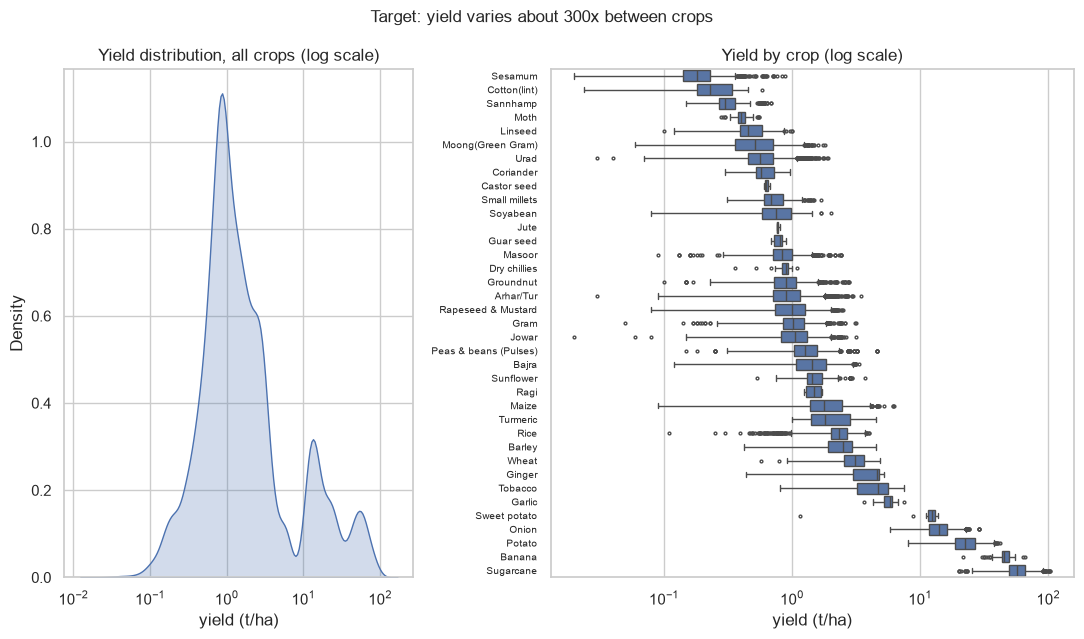

In [26]:
order = df.groupby("crop")["yield_t_per_ha"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1.5]})
sns.kdeplot(df["yield_t_per_ha"], log_scale=True, fill=True, ax=axes[0])
axes[0].set(title="Yield distribution, all crops (log scale)", xlabel="yield (t/ha)")
sns.boxplot(data=df, y="crop", x="yield_t_per_ha", order=order, fliersize=2, ax=axes[1])
axes[1].set(xscale="log", title="Yield by crop (log scale)", xlabel="yield (t/ha)", ylabel="")
fig.suptitle("Target: yield varies about 300x between crops", fontsize=12)
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### Before vs after filling

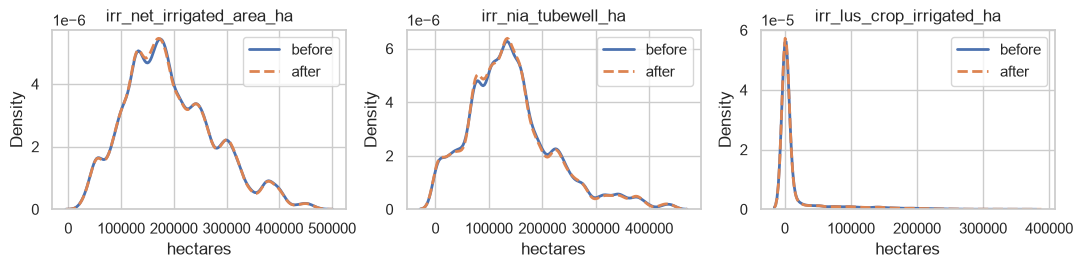

In [27]:
check = ["irr_net_irrigated_area_ha", "irr_nia_tubewell_ha", "irr_lus_crop_irrigated_ha"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, col in zip(axes, check):
    sns.kdeplot(raw[col].dropna(), ax=ax, label="before", lw=2)
    sns.kdeplot(df[col].dropna(), ax=ax, label="after", lw=2, ls="--")
    ax.set(title=col, xlabel="hectares")
    ax.legend()
plt.tight_layout()
plt.show()

### Yield vs irrigation and rainfall

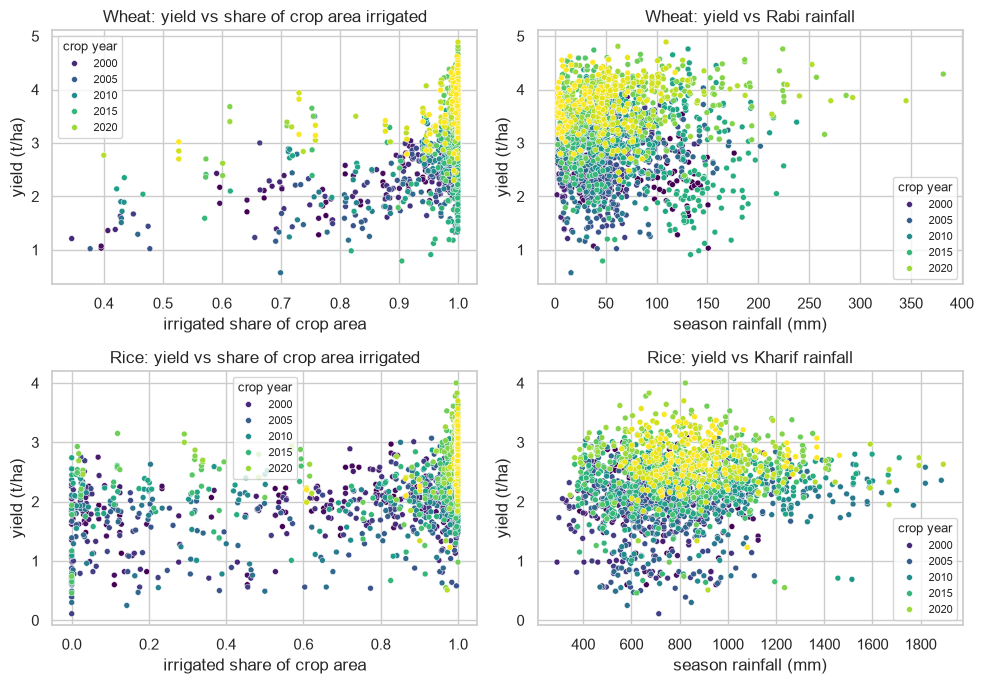

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, (crop, season) in enumerate([("Wheat", "Rabi"), ("Rice", "Kharif")]):
    d = df[(df["crop"] == crop) & (df["season"] == season)]
    irrigated_share = d["irr_lus_crop_irrigated_ha"] / d["irr_lus_crop_area_ha"]
    sns.scatterplot(x=irrigated_share, y=d["yield_t_per_ha"], hue=d["crop_year_start"],
                    palette="viridis", s=18, ax=axes[row, 0])
    axes[row, 0].set(title=f"{crop}: yield vs share of crop area irrigated",
                     xlabel="irrigated share of crop area", ylabel="yield (t/ha)")
    sns.scatterplot(data=d, x="w_rain_total_mm", y="yield_t_per_ha", hue="crop_year_start",
                    palette="viridis", s=18, ax=axes[row, 1])
    axes[row, 1].set(title=f"{crop}: yield vs {season} rainfall", xlabel="season rainfall (mm)", ylabel="yield (t/ha)")
    for ax in axes[row]:
        ax.legend(title="crop year", fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.show()

### Yield trend over years

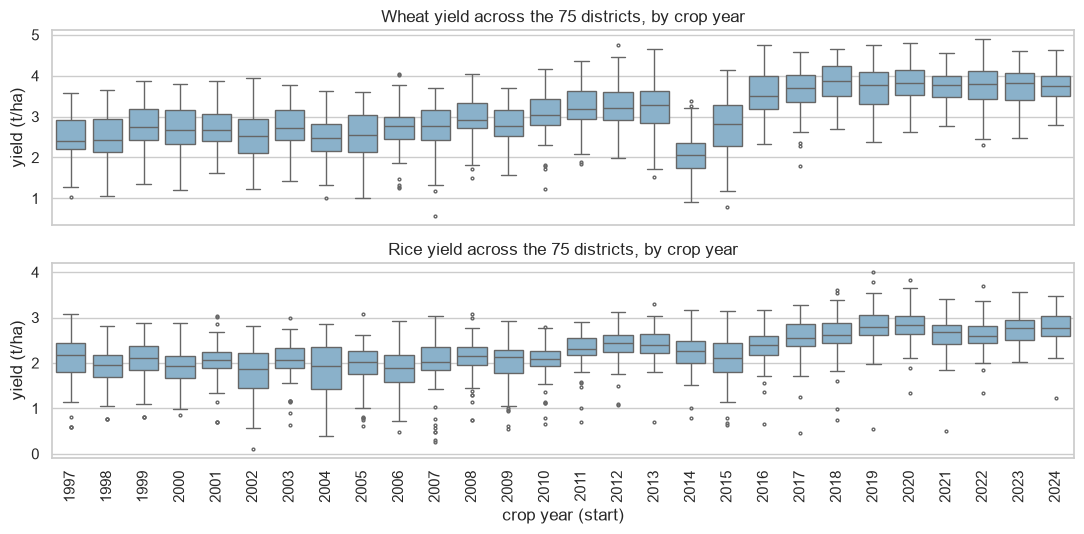

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, (crop, season) in zip(axes, [("Wheat", "Rabi"), ("Rice", "Kharif")]):
    d = df[(df["crop"] == crop) & (df["season"] == season)]
    sns.boxplot(data=d, x="crop_year_start", y="yield_t_per_ha", color="#7fb3d5", fliersize=2, ax=ax)
    ax.set(title=f"{crop} yield across the 75 districts, by crop year", xlabel="", ylabel="yield (t/ha)")
axes[1].set_xlabel("crop year (start)")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

### Feature scales

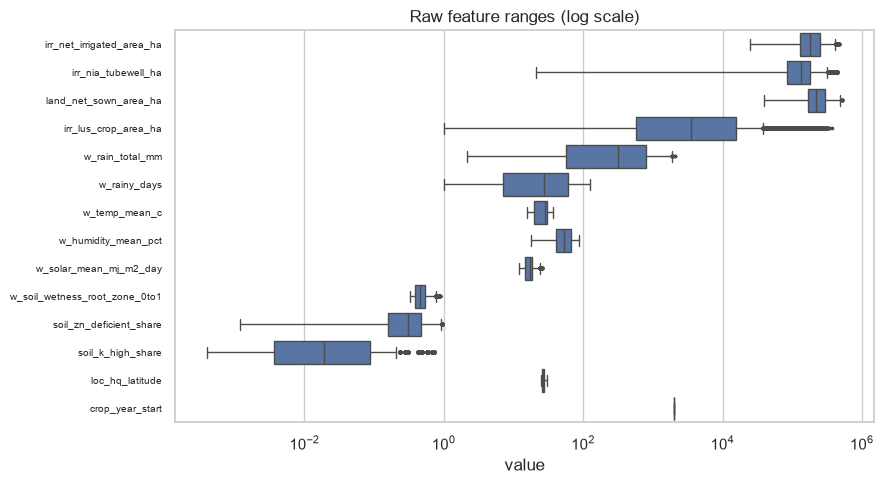

In [30]:
scale_cols = ["irr_net_irrigated_area_ha", "irr_nia_tubewell_ha", "land_net_sown_area_ha", "irr_lus_crop_area_ha",
              "w_rain_total_mm", "w_rainy_days", "w_temp_mean_c", "w_humidity_mean_pct",
              "w_solar_mean_mj_m2_day", "w_soil_wetness_root_zone_0to1", "soil_zn_deficient_share",
              "soil_k_high_share", "loc_hq_latitude", "crop_year_start"]
long = yield_df[scale_cols].melt(var_name="feature", value_name="value")
long = long[long["value"] > 0]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=long, y="feature", x="value", fliersize=1.5, ax=ax)
ax.set(xscale="log", title="Raw feature ranges (log scale)", xlabel="value", ylabel="")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## Scaling Check

In [31]:
num = yield_df.select_dtypes("number").drop(columns=["yield_t_per_ha"])
scale = pd.DataFrame({"min": num.min(), "median": num.median(), "max": num.max(),
                      "std": num.std(), "skew": num.skew()}).round(3)
scale.sort_values("max", ascending=False)

,min,median,max,std,skew
land_gross_cropped_area_ha,74871.000,353461.000,755887.000,141974.380,0.472
irr_gross_irrigated_area_ha,28050.000,263550.000,724233.000,136770.813,0.596
land_net_sown_area_ha,39107.000,219851.000,521845.000,90174.255,0.492
irr_net_irrigated_area_ha,25035.000,179825.000,471800.000,84360.814,0.574
irr_nia_tubewell_ha,0.000,131930.000,442120.000,82078.072,0.909
irr_lus_crop_area_ha,0.000,3445.000,372348.000,44821.854,2.882
irr_lus_crop_irrigated_ha,0.000,414.000,372348.000,42403.394,3.351
irr_nia_other_wells_ha,0.000,1166.000,180628.000,28496.506,2.772
irr_nia_canal_ha,0.000,23642.000,168628.000,32887.733,1.327
irr_nia_other_sources_ha,0.000,48.000,148545.000,6162.498,11.327


## Feature Engineering

### Ratio features (comparable across district sizes)

In [32]:
meta = ["district", "area_ha", "yield_repeated", "price_harvest_state_median"]
fe = yield_df.copy()
fe[meta] = df[meta]

fe["crop_irrigated_share"] = (fe["irr_lus_crop_irrigated_ha"] / fe["irr_lus_crop_area_ha"]).replace([np.inf, -np.inf], np.nan).clip(0, 1)
fe["district_irrigated_share"] = (fe["irr_net_irrigated_area_ha"] / fe["land_net_sown_area_ha"]).clip(0, 1)
fe["irrigation_intensity"] = fe["irr_gross_irrigated_area_ha"] / fe["irr_net_irrigated_area_ha"]
fe["cropping_intensity"] = fe["land_gross_cropped_area_ha"] / fe["land_net_sown_area_ha"]
for source in ["canal", "tank", "tubewell", "other_wells", "other_sources"]:
    fe[f"{source}_share"] = (fe[f"irr_nia_{source}_ha"] / fe["irr_net_irrigated_area_ha"]).clip(0, 1)
fe["crop_irrigated_share_known"] = fe["crop_irrigated_share"].notna().astype(int)
fe["crop_irrigated_share"] = fe["crop_irrigated_share"].fillna(fe["district_irrigated_share"])

district_ratios = ["district_irrigated_share", "irrigation_intensity", "cropping_intensity",
                   "canal_share", "tank_share", "tubewell_share", "other_wells_share", "other_sources_share"]
crop_ratios = ["crop_irrigated_share", "crop_irrigated_share_known"]
fe[district_ratios + crop_ratios].describe().round(3)

,district_irrigated_share,irrigation_intensity,cropping_intensity,canal_share,tank_share,tubewell_share,other_wells_share,other_sources_share,crop_irrigated_share,crop_irrigated_share_known
count,47241.000,47241.000,47241.000,47241.000,47241.000,47241.000,47241.000,47241.000,47241.000,47241.000
mean,0.827,1.482,1.585,0.197,0.010,0.713,0.071,0.009,0.606,0.687
std,0.174,0.305,0.213,0.188,0.028,0.237,0.133,0.027,0.400,0.464
min,0.192,0.405,0.857,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.761,1.305,1.476,0.055,0.000,0.603,0.000,0.000,0.122,0.000
50%,0.884,1.492,1.585,0.143,0.000,0.783,0.008,0.000,0.806,1.000
75%,0.946,1.637,1.689,0.266,0.003,0.887,0.065,0.004,0.974,1.000
max,1.000,7.193,3.486,0.940,0.420,1.000,0.966,0.442,1.000,1.000


### Add empty rows for the next season (features only, the yield is not known yet)

In [33]:
keys = ["district", "crop", "season"]
last_year = int(fe["crop_year_start"].max())
next_label = f"{last_year + 1}-{(last_year + 2) % 100:02d}"
next_rows = fe.loc[fe["crop_year_start"] >= last_year - 2, keys].drop_duplicates().assign(crop_year_start=last_year + 1)
fe = pd.concat([fe, next_rows], ignore_index=True)
for col in ["loc_hq_latitude", "loc_hq_longitude"]:
    fe[col] = fe.groupby("district")[col].transform("first")
print(f"{len(next_rows):,} district-crop-season combinations added for {next_label}")

2,200 district-crop-season combinations added for 2025-26


### Past-yield features (from earlier years only)

In [34]:
fe = fe.sort_values([*keys, "crop_year_start"]).reset_index(drop=True)
own = fe.groupby(keys)["yield_t_per_ha"]
recent = own.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

fe["has_own_history"] = recent.notna().astype(int)
fe["years_of_history"] = fe.groupby(keys).cumcount()
fe["last_year_vs_recent"] = (own.shift(1) / recent).fillna(1)
fe["long_run_vs_recent"] = (own.transform(lambda s: s.shift(1).expanding().mean()) / recent).fillna(1)

state = fe.groupby(["crop", "season", "crop_year_start"], as_index=False)["yield_t_per_ha"].median().sort_values("crop_year_start")
by_crop = state.groupby(["crop", "season"])["yield_t_per_ha"]
state["state_recent"] = by_crop.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
state["state_change_last_year"] = (by_crop.shift(1) / by_crop.shift(2)).fillna(1)
fe = fe.merge(state.drop(columns="yield_t_per_ha"), on=["crop", "season", "crop_year_start"], how="left")

fe["yield_recent_mean"] = recent.fillna(fe["state_recent"])
fe["state_vs_recent"] = fe["state_recent"] / fe["yield_recent_mean"]
fe = fe.drop(columns="state_recent")
history_cols = ["yield_recent_mean", "has_own_history", "years_of_history", "last_year_vs_recent",
                "long_run_vs_recent", "state_vs_recent", "state_change_last_year"]
fe[history_cols].describe().round(3)

,yield_recent_mean,has_own_history,years_of_history,last_year_vs_recent,long_run_vs_recent,state_vs_recent,state_change_last_year
count,47142.000,49441.000,49441.000,49441.000,49441.000,47142.000,49441.000
mean,5.693,0.941,11.076,1.016,0.960,1.043,1.035
std,12.545,0.236,7.722,0.171,0.157,0.285,0.239
min,0.043,0.000,0.000,0.020,0.389,0.237,0.098
25%,0.730,1.000,4.000,0.956,0.877,0.935,0.952
50%,1.220,1.000,10.000,1.000,0.990,1.000,1.004
75%,2.805,1.000,17.000,1.081,1.003,1.086,1.084
max,102.430,1.000,28.000,2.413,4.492,12.062,9.111


### Expected weather: average of the previous 3 years for the same district and season

In [35]:
weather_cols = ["w_rain_total_mm", "w_temp_mean_c", "w_max_1day_rain_mm", "w_solar_mean_mj_m2_day",
                "w_humidity_mean_pct", "w_cold_days_tmin_le_5", "w_hot_days_tmax_ge_35", "w_soil_wetness_root_zone_0to1"]
expected_cols = [c + "_expected" for c in weather_cols]
place = ["district", "season", "crop_year_start"]
seasons = fe.drop_duplicates(place).sort_values("crop_year_start")[place + weather_cols].copy()
for col in weather_cols:
    seasons[col + "_expected"] = seasons.groupby(["district", "season"])[col].transform(
        lambda s: s.shift(1).rolling(3, min_periods=1).mean())
fe = fe.merge(seasons.drop(columns=weather_cols), on=place, how="left")
fe[expected_cols].describe().round(2)

,w_rain_total_mm_expected,w_temp_mean_c_expected,w_max_1day_rain_mm_expected,w_solar_mean_mj_m2_day_expected,w_humidity_mean_pct_expected,w_cold_days_tmin_le_5_expected,w_hot_days_tmax_ge_35_expected,w_soil_wetness_root_zone_0to1_expected
count,47804.00,47804.00,47804.00,47804.00,47804.00,47804.00,47804.00,47804.00
mean,437.07,25.93,40.23,17.24,52.64,2.49,47.14,0.47
std,393.05,5.80,25.97,2.78,14.64,4.00,34.63,0.10
min,8.17,15.92,2.34,12.70,17.97,0.00,0.00,0.33
25%,64.39,19.51,17.41,14.87,41.66,0.00,16.67,0.39
50%,246.29,28.99,37.24,17.42,52.55,0.00,41.00,0.46
75%,771.03,30.10,57.83,18.31,66.36,4.00,72.67,0.54
max,1797.76,36.22,167.46,25.28,81.31,26.00,210.00,0.79


### Last year's irrigation and land-use ratios

In [36]:
by_district = fe.drop_duplicates(["district", "crop_year_start"]).sort_values("crop_year_start")[["district", "crop_year_start", *district_ratios]].copy()
previous_cols = [c + "_prev" for c in district_ratios]
by_district[previous_cols] = by_district.groupby("district")[district_ratios].shift(1).to_numpy()
fe = fe.merge(by_district.drop(columns=district_ratios), on=["district", "crop_year_start"], how="left")
for col in district_ratios:
    fe[col + "_prev"] = fe[col + "_prev"].fillna(fe[col])

fe = fe.sort_values([*keys, "crop_year_start"]).reset_index(drop=True)
by_group = fe.groupby(keys)
fe["crop_irrigated_share_prev"] = by_group["crop_irrigated_share"].shift(1).fillna(fe["district_irrigated_share_prev"])
fe["crop_irrigated_share_known_prev"] = by_group["crop_irrigated_share_known"].shift(1).fillna(0).astype(int)
irrigation_cols = previous_cols + ["crop_irrigated_share_prev", "crop_irrigated_share_known_prev"]
fe[irrigation_cols].describe().round(3)

,district_irrigated_share_prev,irrigation_intensity_prev,cropping_intensity_prev,canal_share_prev,tank_share_prev,tubewell_share_prev,other_wells_share_prev,other_sources_share_prev,crop_irrigated_share_prev,crop_irrigated_share_known_prev
count,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000
mean,0.825,1.479,1.582,0.198,0.010,0.712,0.070,0.009,0.614,0.651
std,0.175,0.303,0.212,0.189,0.028,0.238,0.132,0.028,0.394,0.477
min,0.192,0.405,0.857,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.759,1.303,1.475,0.056,0.000,0.603,0.000,0.000,0.148,0.000
50%,0.883,1.491,1.583,0.145,0.000,0.781,0.008,0.000,0.808,1.000
75%,0.946,1.635,1.685,0.268,0.003,0.886,0.064,0.005,0.970,1.000
max,1.000,7.193,3.486,0.940,0.420,1.000,0.966,0.442,1.000,1.000


### Soil health card: share of tested samples in each class (one survey of 2023-26, the same for every year)

In [37]:
soil_cols = [c for c in fe.columns if c.startswith("soil_") and c.endswith("_share")]
fe[soil_cols] = fe.groupby("district")[soil_cols].transform("first")
fe[soil_cols].describe().round(3)

,soil_n_high_share,soil_n_low_share,soil_n_medium_share,soil_p_high_share,soil_p_low_share,soil_p_medium_share,soil_k_high_share,soil_k_low_share,soil_k_medium_share,soil_oc_high_share,soil_oc_low_share,soil_oc_medium_share,soil_ph_alkaline_share,soil_ph_acidic_share,soil_ph_neutral_share,soil_ec_saline_share,soil_s_deficient_share,soil_zn_deficient_share,soil_fe_deficient_share,soil_cu_deficient_share,soil_b_deficient_share,soil_mn_deficient_share
count,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000,49441.000
mean,0.001,0.959,0.041,0.178,0.204,0.619,0.110,0.103,0.787,0.012,0.851,0.136,0.008,0.001,0.991,0.015,0.342,0.340,0.270,0.046,0.315,0.104
std,0.001,0.069,0.069,0.159,0.152,0.150,0.191,0.129,0.200,0.029,0.142,0.124,0.027,0.001,0.028,0.074,0.310,0.224,0.232,0.048,0.267,0.147
min,0.000,0.647,0.000,0.002,0.003,0.337,0.000,0.000,0.182,0.000,0.284,0.000,0.000,0.000,0.793,0.000,0.001,0.001,0.001,0.000,0.001,0.000
25%,0.000,0.953,0.000,0.039,0.076,0.503,0.004,0.020,0.685,0.001,0.781,0.035,0.000,0.000,0.993,0.000,0.071,0.159,0.091,0.002,0.074,0.006
50%,0.000,0.995,0.005,0.123,0.180,0.598,0.019,0.067,0.858,0.004,0.893,0.103,0.001,0.000,0.998,0.001,0.246,0.311,0.185,0.031,0.283,0.057
75%,0.001,0.999,0.044,0.283,0.302,0.733,0.087,0.134,0.931,0.013,0.962,0.204,0.006,0.000,0.999,0.004,0.550,0.467,0.427,0.078,0.514,0.120
max,0.004,1.000,0.353,0.616,0.659,0.920,0.730,0.792,0.995,0.216,0.999,0.512,0.206,0.006,1.000,0.587,0.996,0.952,0.836,0.204,0.982,0.753


### Keep only what is known before sowing

In [38]:
feature_cols = ["crop", "season", "crop_year_start", "loc_hq_latitude", "loc_hq_longitude",
                *history_cols, *expected_cols, *irrigation_cols, *soil_cols]
set_aside = [c for c in fe.columns if c not in feature_cols + meta + ["yield_t_per_ha"]]
fe = fe[feature_cols + ["yield_t_per_ha"] + meta]
print(len(feature_cols), "features kept")
print(len(set_aside), "columns set aside (soil sample counts and village spread, the season's own weather, the year's own irrigation figures)")

52 features kept
45 columns set aside (soil sample counts and village spread, the season's own weather, the year's own irrigation figures)


### Set aside the next-season rows and drop rows with no earlier year

In [39]:
next_season = fe[fe["yield_t_per_ha"].isna()][["district", *feature_cols]].dropna().reset_index(drop=True)
fe = fe[fe["yield_t_per_ha"].notna()].astype({"yield_repeated": bool})
before = len(fe)
fe = fe.dropna(subset=feature_cols).reset_index(drop=True)
print(f"Next-season rows ({next_label}): {len(next_season):,}")
print(f"Dropped {before - len(fe):,} rows with no earlier year -> {len(fe):,} rows | nulls left: {fe[feature_cols].isna().sum().sum()}")

Next-season rows (2025-26): 2,200
Dropped 2,408 rows with no earlier year -> 44,833 rows | nulls left: 0


### Train/test split by year (train 1998-2019, test 2020-2024)

In [40]:
fe = fe.sort_values("crop_year_start", kind="stable").reset_index(drop=True)
X, y = fe[feature_cols], fe["yield_t_per_ha"]

test_share = (fe["crop_year_start"] >= 2020).mean()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_share, shuffle=False)
district_train, district_test = fe.loc[X_train.index, "district"], fe.loc[X_test.index, "district"]

print("Train:", X_train.shape, X_train["crop_year_start"].min(), "-", X_train["crop_year_start"].max())
print("Test: ", X_test.shape, X_test["crop_year_start"].min(), "-", X_test["crop_year_start"].max())

Train: (36417, 52) 1998 - 2019
Test:  (8416, 52) 2020 - 2024


### Target: raw vs log

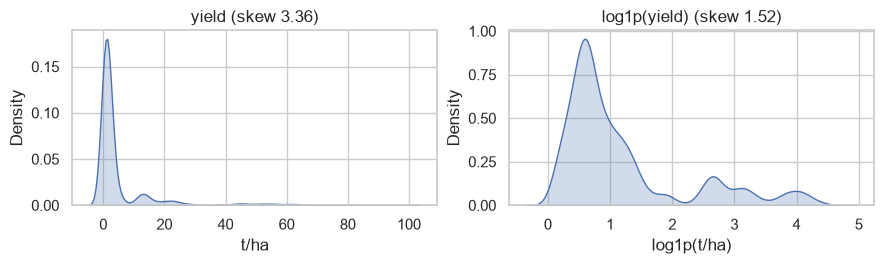

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
sns.kdeplot(y_train, fill=True, ax=axes[0])
axes[0].set(title=f"yield (skew {y_train.skew():.2f})", xlabel="t/ha")
sns.kdeplot(np.log1p(y_train), fill=True, ax=axes[1])
axes[1].set(title=f"log1p(yield) (skew {np.log1p(y_train).skew():.2f})", xlabel="log1p(t/ha)")
plt.tight_layout()
plt.show()

### Skewed count and amount features to log-transform (skew > 1, found on train)

In [42]:
cat_cols = ["crop", "season"]
flag_cols = ["has_own_history", "crop_irrigated_share_known_prev"]
num_cols = [c for c in feature_cols if c not in cat_cols + flag_cols]

skew_before = X_train[num_cols].skew()
skewed = [c for c in num_cols if skew_before[c] > 1 and X_train[c].min() >= 0 and X_train[c].max() > 1]
X_eda = X_train.copy()
X_eda[skewed] = np.log1p(X_eda[skewed])

pd.DataFrame({"skew_before": skew_before[skewed], "skew_after": X_eda[skewed].skew()}).round(2)

,skew_before,skew_after
yield_recent_mean,3.30,1.54
long_run_vs_recent,3.36,1.54
state_vs_recent,5.40,1.77
state_change_last_year,7.84,2.07
w_cold_days_tmin_le_5_expected,2.15,0.81


### Correlation heatmap

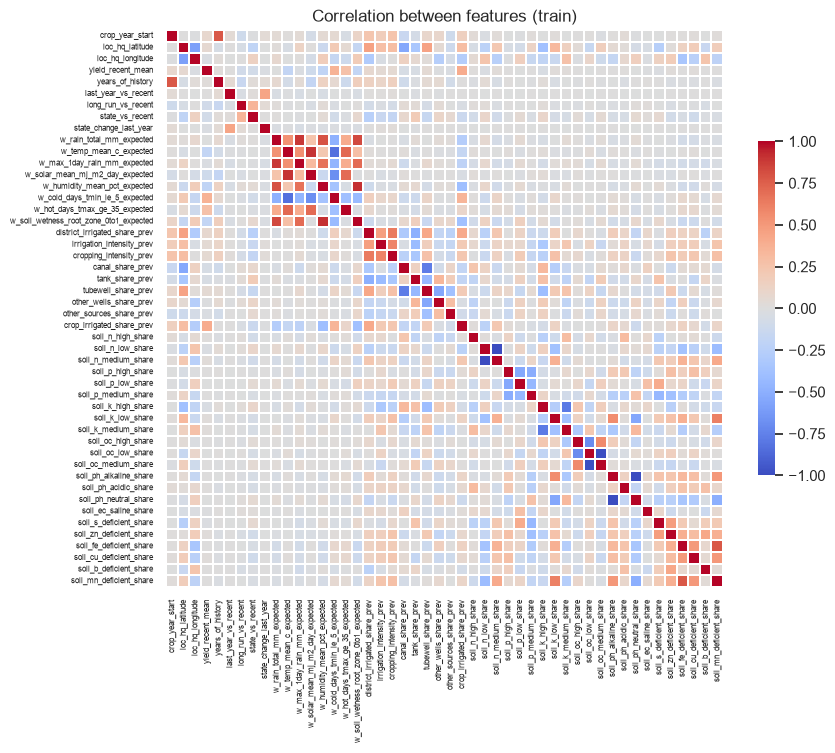

In [43]:
corr = X_eda[num_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.6}, xticklabels=True, yticklabels=True, ax=ax)
ax.set_title("Correlation between features (train)", fontsize=12)
ax.tick_params(labelsize=6)
plt.tight_layout()
plt.show()

### Highly correlated pairs (|r| > 0.9)

In [44]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("r").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
pairs = pairs[pairs["r"].abs() > 0.9].sort_values("r", key=abs, ascending=False)
pairs.round(3)

,feature_1,feature_2,r
1324,soil_n_low_share,soil_n_medium_share,-1.000
1864,soil_ph_alkaline_share,soil_ph_neutral_share,-0.999
1765,soil_oc_low_share,soil_oc_medium_share,-0.986
640,w_humidity_mean_pct_expected,w_soil_wetness_root_zone_0to1_expected,0.912
492,w_temp_mean_c_expected,w_solar_mean_mj_m2_day_expected,0.905


### Human-known essential features (never dropped)

In [45]:
essential = ["crop", "season", "crop_year_start", "yield_recent_mean",
             "w_rain_total_mm_expected", "w_temp_mean_c_expected",
             "crop_irrigated_share_prev", "district_irrigated_share_prev",
             "soil_ph_alkaline_share", "soil_ec_saline_share", "soil_oc_low_share", "soil_n_low_share",
             "soil_p_low_share", "soil_k_low_share", "soil_zn_deficient_share"]
print(len(essential), "essential features")

15 essential features


### Features to drop: one from each pair above 0.95 (essential ones are kept)

In [46]:
to_drop = []
for row in pairs[pairs["r"].abs() > 0.95].itertuples():
    if row.feature_1 in to_drop or row.feature_2 in to_drop:
        continue
    candidate = row.feature_1 if row.feature_2 in essential else row.feature_2
    if candidate not in essential:
        to_drop.append(candidate)

num_cols = [c for c in num_cols if c not in to_drop]
print("Dropped:", to_drop)

Dropped: ['soil_n_medium_share', 'soil_ph_neutral_share', 'soil_oc_medium_share']


### Correlation with yield relative to the crop's median (train)

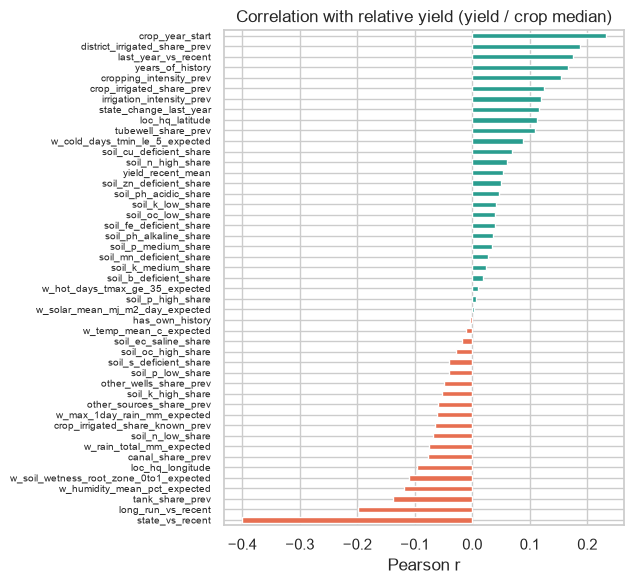

In [47]:
relative_yield = y_train / y_train.groupby(X_train["crop"]).transform("median")
target_corr = X_eda[num_cols + flag_cols].corrwith(relative_yield).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 6))
target_corr.plot.barh(color=np.where(target_corr > 0, "#2a9d8f", "#e76f51"), ax=ax)
ax.set(title="Correlation with relative yield (yield / crop median)", xlabel="Pearson r")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### ColumnTransformer: log, scale, one-hot, drop correlated (fitted on train)

In [48]:
def make_preprocessor(columns):
    numeric = [c for c in columns if c not in cat_cols + flag_cols]
    return ColumnTransformer(
        [("log_scale", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                 ("scale", StandardScaler())]), [c for c in numeric if c in skewed]),
         ("scale", StandardScaler(), [c for c in numeric if c not in skewed]),
         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), [c for c in columns if c in cat_cols]),
         ("flag", "passthrough", [c for c in columns if c in flag_cols])],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

input_columns = feature_cols
model_columns = [c for c in input_columns if c not in to_drop]
preprocessor = make_preprocessor(model_columns)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(len(input_columns), "input columns |", len(model_columns), "after the correlation filter")
print("X_train_prep:", X_train_prep.shape, "| X_test_prep:", X_test_prep.shape)
X_train_prep[num_cols].describe().loc[["mean", "std"]].round(2)

52 input columns | 49 after the correlation filter
X_train_prep: (36417, 88) | X_test_prep: (8416, 88)


,crop_year_start,loc_hq_latitude,loc_hq_longitude,yield_recent_mean,years_of_history,last_year_vs_recent,long_run_vs_recent,state_vs_recent,state_change_last_year,w_rain_total_mm_expected,w_temp_mean_c_expected,w_max_1day_rain_mm_expected,w_solar_mean_mj_m2_day_expected,w_humidity_mean_pct_expected,w_cold_days_tmin_le_5_expected,w_hot_days_tmax_ge_35_expected,w_soil_wetness_root_zone_0to1_expected,district_irrigated_share_prev,irrigation_intensity_prev,cropping_intensity_prev,canal_share_prev,tank_share_prev,tubewell_share_prev,other_wells_share_prev,other_sources_share_prev,crop_irrigated_share_prev,soil_n_high_share,soil_n_low_share,soil_p_high_share,soil_p_low_share,soil_p_medium_share,soil_k_high_share,soil_k_low_share,soil_k_medium_share,soil_oc_high_share,soil_oc_low_share,soil_ph_alkaline_share,soil_ph_acidic_share,soil_ec_saline_share,soil_s_deficient_share,soil_zn_deficient_share,soil_fe_deficient_share,soil_cu_deficient_share,soil_b_deficient_share,soil_mn_deficient_share
mean,0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### PCA: explained variance

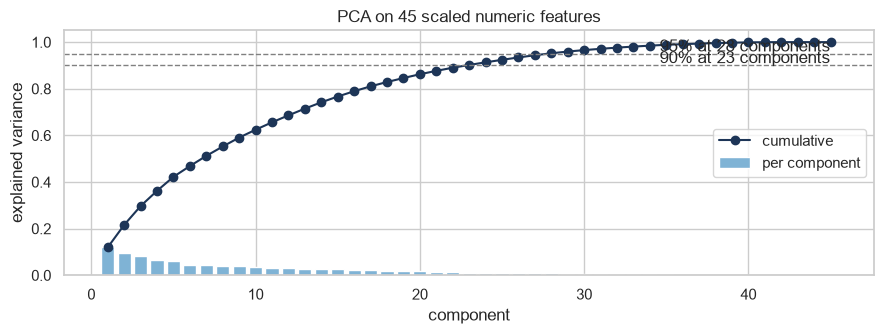

In [49]:
pca = PCA().fit(X_train_prep[num_cols])
cumulative = np.cumsum(pca.explained_variance_ratio_)
n90, n95 = np.searchsorted(cumulative, 0.90) + 1, np.searchsorted(cumulative, 0.95) + 1

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(1, len(cumulative) + 1), pca.explained_variance_ratio_, color="#7fb3d5", label="per component")
ax.plot(range(1, len(cumulative) + 1), cumulative, marker="o", color="#1d3557", label="cumulative")
for level, n in [(0.90, n90), (0.95, n95)]:
    ax.axhline(level, ls="--", color="grey", lw=1)
    ax.text(len(cumulative), level + 0.01, f"{int(level * 100)}% at {n} components", ha="right")
ax.set(title=f"PCA on {len(num_cols)} scaled numeric features", xlabel="component", ylabel="explained variance")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

### PCA: loadings of the first 8 components

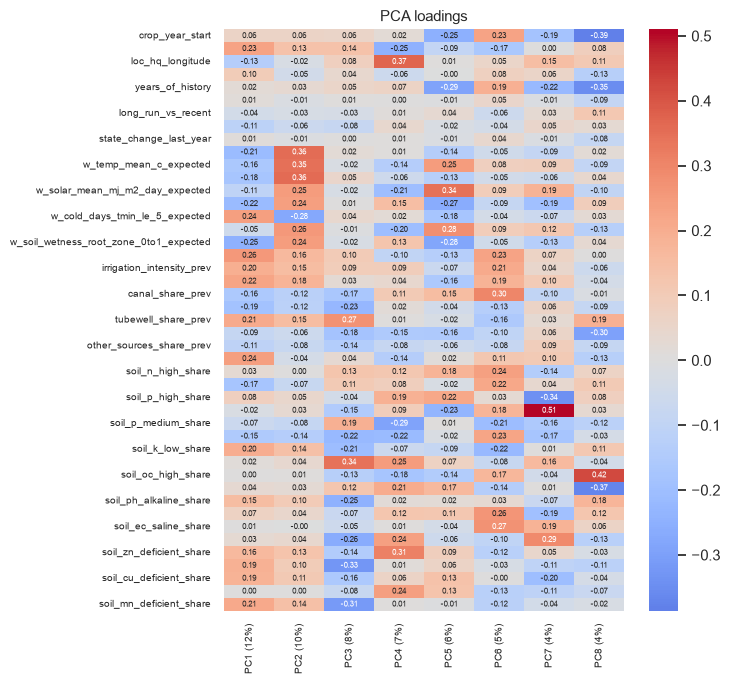

In [50]:
loadings = pd.DataFrame(pca.components_[:8].T, index=num_cols,
                        columns=[f"PC{i + 1} ({v:.0%})" for i, v in enumerate(pca.explained_variance_ratio_[:8])])

fig, ax = plt.subplots(figsize=(7.5, 7))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 5.5}, ax=ax)
ax.set_title("PCA loadings", fontsize=11)
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

## Model A: Yield Model

### Save model-ready data

In [51]:
fe.to_csv("data/processed/model_a_data.csv", index=False)
print(fe.shape)

(44833, 57)


### Evaluation metrics

In [52]:
crop_median = y_train.groupby(X_train["crop"]).median()
area_test = fe.loc[X_test.index, "area_ha"]
repeated_test = fe.loc[X_test.index, "yield_repeated"].astype(bool)

def evaluate(name, predict):
    pred_train, pred = np.asarray(predict(X_train)), np.asarray(predict(X_test))
    ape = np.abs(pred - y_test) / y_test
    med = X_test["crop"].map(crop_median).to_numpy()
    known = ~np.isnan(med)
    return {
        "model": name,
        "train_R2": r2_score(y_train, pred_train),
        "test_R2": r2_score(y_test, pred),
        "within_crop_R2": r2_score(y_test[known] / med[known], pred[known] / med[known]),
        "MAE_t_ha": mean_absolute_error(y_test, pred),
        "MAPE_%": ape.mean() * 100,
        "median_APE_%": ape.median() * 100,
        "accuracy_within_20%": (ape <= 0.20).mean() * 100,
        "area_weighted_accuracy_%": np.average(ape <= 0.20, weights=area_test) * 100,
    }

### Cross-validation folds: by year and by district

In [53]:
years = X_train["crop_year_start"].to_numpy()
year_folds = [(np.where(years < start)[0], np.where((years >= start) & (years <= start + 2))[0])
              for start in (2011, 2014, 2017)]
district_folds = list(GroupKFold(n_splits=5).split(X_train, groups=district_train))

def cv_scores(estimator, folds):
    rows = []
    for fit_idx, val_idx in folds:
        X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]
        if estimator is None:
            pred = X_val["yield_recent_mean"]
        else:
            pred = clone(estimator).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx]).predict(X_val)
        ape = np.abs(np.asarray(pred) - y_val) / y_val
        rows.append({"accuracy_within_20%": (ape <= 0.20).mean() * 100, "MAPE_%": ape.mean() * 100,
                     "median_APE_%": ape.median() * 100})
    return pd.DataFrame(rows)

for fit_idx, val_idx in year_folds:
    print(f"Year fold: train {years[fit_idx].min()}-{years[fit_idx].max()} ({len(fit_idx):,} rows) | validate {years[val_idx].min()}-{years[val_idx].max()} ({len(val_idx):,} rows)")
print("District folds: 5 folds, each validates on", district_train.iloc[district_folds[0][1]].nunique(), "districts the model never saw")

Year fold: train 1998-2010 (19,150 rows) | validate 2011-2013 (5,716 rows)
Year fold: train 1998-2013 (24,866 rows) | validate 2014-2016 (5,676 rows)
Year fold: train 1998-2016 (30,542 rows) | validate 2017-2019 (5,875 rows)
District folds: 5 folds, each validates on 15 districts the model never saw


### Baselines

In [54]:
season_median = y_train.groupby([X_train["crop"], X_train["season"]]).median()

def median_baseline(X):
    keys = pd.MultiIndex.from_frame(X[["crop", "season"]])
    return pd.Series(season_median.reindex(keys).to_numpy(), index=X.index).fillna(X["yield_recent_mean"]).to_numpy()

def history_baseline(X):
    return X["yield_recent_mean"].to_numpy()

MEDIAN_BASELINE, HISTORY_BASELINE = "Baseline: crop-season median", "Baseline: district's previous 3 years"
results = [evaluate(MEDIAN_BASELINE, median_baseline),
           {**evaluate(HISTORY_BASELINE, history_baseline),
            "cv_accuracy_within_20%": cv_scores(None, year_folds)["accuracy_within_20%"].mean()}]
pd.DataFrame(results).set_index("model").round(3)

,train_R2,test_R2,within_crop_R2,MAE_t_ha,MAPE_%,median_APE_%,accuracy_within_20%,area_weighted_accuracy_%,cv_accuracy_within_20%
model,,,,,,,,,
Baseline: crop-season median,0.949,0.903,-0.518,1.337,27.056,23.345,41.374,36.326,NaN
Baseline: district's previous 3 years,0.975,0.989,0.356,0.505,17.413,9.123,75.214,90.847,64.803


### Model pipelines

In [55]:
def build(model, target, columns=None):
    pipeline = Pipeline([("prep", make_preprocessor(columns or model_columns)), ("model", model)])
    if target == "log":
        return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)
    return HistoryAdjustedRegressor(regressor=pipeline, reference_col="yield_recent_mean")

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.5,
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.7,
                            objective="reg:absoluteerror", n_jobs=-1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8,
                              subsample_freq=1, colsample_bytree=0.7, objective="l1", random_state=42, verbose=-1),
}
TARGETS = {"log": "log target", "history": "history-adjusted"}
build(models["LightGBM"], "history")

,regressor,Pipeline(step...verbose=-1))])
,reference_col,'yield_recent_mean'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_scale', ...), ('scale', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights trans

### Train and evaluate every model (log target and history-adjusted target)

In [56]:
for name, model in models.items():
    for target, label in TARGETS.items():
        estimator = build(clone(model), target)
        fitted = clone(estimator).fit(X_train, y_train)
        results.append({**evaluate(f"{name} ({label})", fitted.predict),
                        "cv_accuracy_within_20%": cv_scores(estimator, year_folds)["accuracy_within_20%"].mean()})

def results_table():
    table = pd.DataFrame(results).set_index("model")
    return table[["cv_accuracy_within_20%"] + [c for c in table.columns if c != "cv_accuracy_within_20%"]].round(3)

comparison = results_table()
comparison.sort_values("cv_accuracy_within_20%", ascending=False)

,cv_accuracy_within_20%,train_R2,test_R2,within_crop_R2,MAE_t_ha,MAPE_%,median_APE_%,accuracy_within_20%,area_weighted_accuracy_%
model,,,,,,,,,
XGBoost (history-adjusted),67.755,0.984,0.991,0.428,0.456,16.366,8.991,76.770,89.885
LightGBM (history-adjusted),67.441,0.986,0.991,0.423,0.443,16.432,9.134,76.747,90.103
LightGBM (log target),66.558,0.985,0.982,0.383,0.609,17.521,10.567,74.156,88.030
Random Forest (history-adjusted),66.405,0.997,0.991,0.389,0.473,16.990,10.227,74.976,88.794
XGBoost (log target),66.379,0.988,0.982,0.407,0.630,17.415,10.115,75.083,87.769
Linear Regression (log target),65.574,0.978,0.984,0.344,0.627,18.603,11.762,73.265,89.459
Random Forest (log target),65.175,0.997,0.985,0.368,0.597,17.828,10.731,72.802,87.199
Baseline: district's previous 3 years,64.803,0.975,0.989,0.356,0.505,17.413,9.123,75.214,90.847
Linear Regression (history-adjusted),63.292,0.976,0.977,0.334,0.723,18.344,12.413,72.422,86.744


### Model comparison

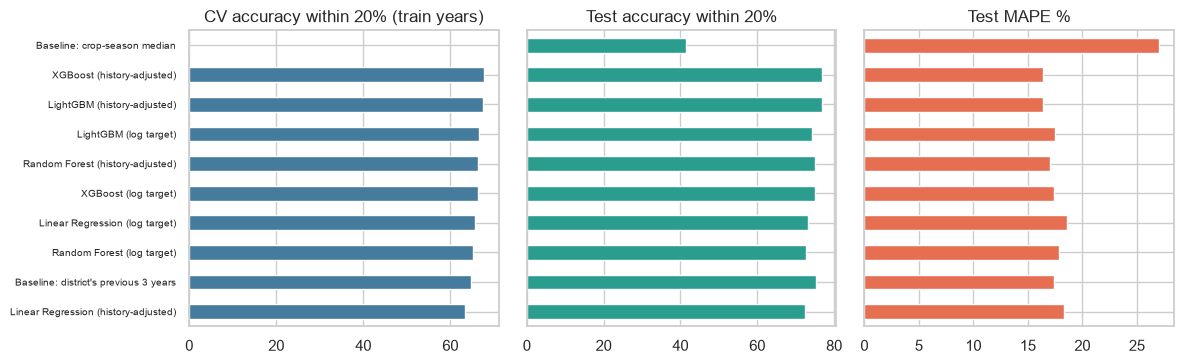

In [57]:
plot = comparison.sort_values("cv_accuracy_within_20%")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, metric, color in zip(axes, ["cv_accuracy_within_20%", "accuracy_within_20%", "MAPE_%"], ["#457b9d", "#2a9d8f", "#e76f51"]):
    plot[metric].plot.barh(ax=ax, color=color)
    ax.set(title={"cv_accuracy_within_20%": "CV accuracy within 20% (train years)",
                  "accuracy_within_20%": "Test accuracy within 20%", "MAPE_%": "Test MAPE %"}[metric], ylabel="")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### Choose the model by cross-validated accuracy within 20%, then tune it

In [58]:
best_name = comparison["cv_accuracy_within_20%"].drop(index=[MEDIAN_BASELINE, HISTORY_BASELINE]).idxmax()
family = best_name.split(" (")[0]
best_target = "log" if "log target" in best_name else "history"
print("Best model by cross-validation:", best_name)

within_20 = make_scorer(lambda y_true, y_hat: np.mean(np.abs(y_hat - y_true) / y_true <= 0.20))
grids = {
    "LightGBM": {"n_estimators": [300, 500, 800], "learning_rate": [0.02, 0.03, 0.05], "num_leaves": [15, 31, 63],
                 "min_child_samples": [20, 40, 80], "colsample_bytree": [0.5, 0.7, 0.9], "reg_lambda": [0, 1, 5],
                 "objective": ["l1", "huber"]},
    "XGBoost": {"n_estimators": [300, 500, 800], "learning_rate": [0.02, 0.03, 0.05], "max_depth": [4, 5, 7],
                "min_child_weight": [1, 5, 10], "colsample_bytree": [0.5, 0.7, 0.9], "reg_lambda": [0, 1, 5]},
    "Random Forest": {"n_estimators": [200, 400], "max_features": [0.3, 0.5, 0.7], "min_samples_leaf": [1, 3, 5]},
    "Linear Regression": {"fit_intercept": [True]},
}
search = RandomizedSearchCV(
    build(clone(models[family]), best_target),
    {"regressor__model__" + k: v for k, v in grids[family].items()},
    n_iter={"LightGBM": 12, "XGBoost": 12, "Random Forest": 6, "Linear Regression": 1}[family],
    cv=year_folds, scoring=within_20, random_state=42, n_jobs=1,
).fit(X_train, y_train)

tuned_cv, default_cv = search.best_score_ * 100, comparison.loc[best_name, "cv_accuracy_within_20%"]
best_model = clone(search.best_estimator_.regressor.named_steps["model"]) if tuned_cv > default_cv else clone(models[family])
print("Best parameters:", {k.replace("regressor__model__", ""): v for k, v in search.best_params_.items()})
print(f"CV accuracy within 20%: default {default_cv:.2f} | tuned {tuned_cv:.2f} ->", "tuned" if tuned_cv > default_cv else "default", "settings kept")

Best model by cross-validation: XGBoost (history-adjusted)


Best parameters: {'reg_lambda': 1, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.5}
CV accuracy within 20%: default 67.75 | tuned 68.17 -> tuned settings kept


### Chi-square test: which features are related to yield going above or below the recent level?

In [59]:
change = np.log(y_train / X_train["yield_recent_mean"])
change_class = pd.qcut(change, 4, labels=["much lower", "lower", "higher", "much higher"])

rows = []
for col in input_columns:
    values = X_train[col]
    binned = values if col in cat_cols or values.nunique() <= 5 else pd.qcut(values, 5, labels=False, duplicates="drop")
    table = pd.crosstab(binned, change_class)
    chi2_stat, p_value, _, _ = chi2_contingency(table)
    rows.append({"feature": col, "chi2": chi2_stat, "p_value": p_value,
                 "cramers_v": np.sqrt(chi2_stat / (table.to_numpy().sum() * max(min(table.shape) - 1, 1)))})
chi_table = pd.DataFrame(rows).set_index("feature").sort_values("chi2", ascending=False)
chi_table.round(4)

,chi2,p_value,cramers_v
feature,,,
crop,6293.2906,0.0000,0.2400
last_year_vs_recent,4482.2255,0.0000,0.2026
state_change_last_year,2646.8351,0.0000,0.1557
state_vs_recent,2275.9682,0.0000,0.1443
yield_recent_mean,1924.7692,0.0000,0.1327
crop_year_start,1689.3687,0.0000,0.1244
long_run_vs_recent,1536.4003,0.0000,0.1186
crop_irrigated_share_prev,1305.7759,0.0000,0.1093
season,775.3610,0.0000,0.0842


### Feature selection: essential features + top 15 by chi-square

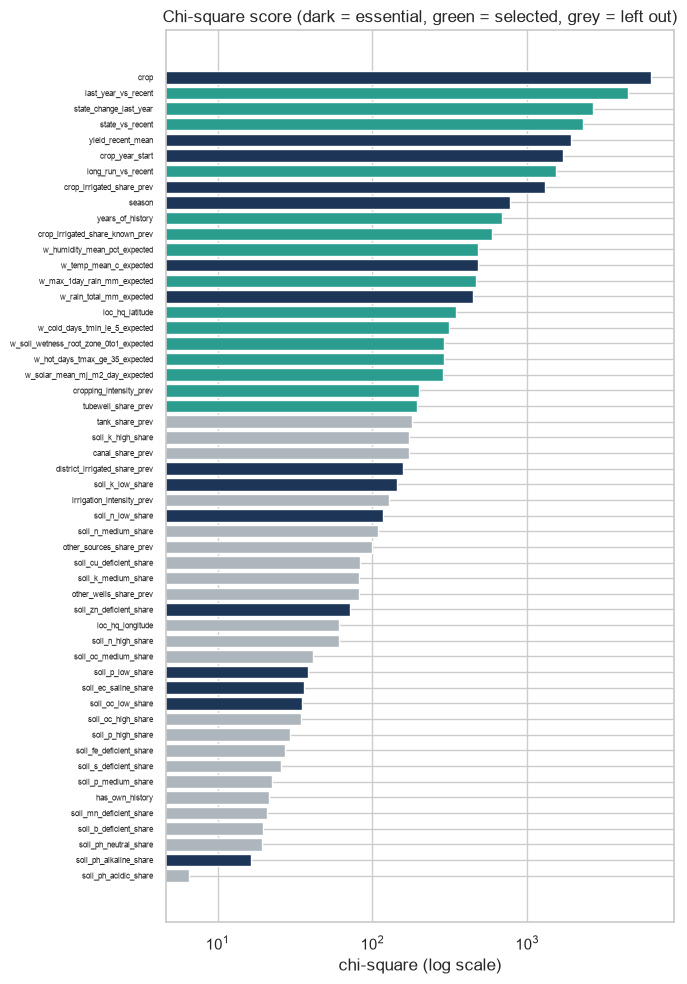

Not significant (p >= 0.05): ['soil_mn_deficient_share', 'soil_b_deficient_share', 'soil_ph_neutral_share', 'soil_ph_alkaline_share', 'soil_ph_acidic_share']
30 features selected: ['crop', 'season', 'crop_year_start', 'yield_recent_mean', 'w_rain_total_mm_expected', 'w_temp_mean_c_expected', 'crop_irrigated_share_prev', 'district_irrigated_share_prev', 'soil_ph_alkaline_share', 'soil_ec_saline_share', 'soil_oc_low_share', 'soil_n_low_share', 'soil_p_low_share', 'soil_k_low_share', 'soil_zn_deficient_share', 'last_year_vs_recent', 'state_change_last_year', 'state_vs_recent', 'long_run_vs_recent', 'years_of_history', 'crop_irrigated_share_known_prev', 'w_humidity_mean_pct_expected', 'w_max_1day_rain_mm_expected', 'loc_hq_latitude', 'w_cold_days_tmin_le_5_expected', 'w_soil_wetness_root_zone_0to1_expected', 'w_hot_days_tmax_ge_35_expected', 'w_solar_mean_mj_m2_day_expected', 'cropping_intensity_prev', 'tubewell_share_prev']


In [60]:
chi_candidates = [c for c in chi_table.index if c not in essential and c not in to_drop]
chi_selected = [c for c in chi_candidates if chi_table.loc[c, "p_value"] < 0.05][:15]
selected = essential + chi_selected

colors = ["#1d3557" if c in essential else "#2a9d8f" if c in chi_selected else "#adb5bd" for c in chi_table.index]
fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(chi_table.index, chi_table["chi2"], color=colors)
ax.invert_yaxis()
ax.set(xscale="log", title="Chi-square score (dark = essential, green = selected, grey = left out)", xlabel="chi-square (log scale)")
ax.tick_params(axis="y", labelsize=6)
plt.tight_layout()
plt.show()

print("Not significant (p >= 0.05):", chi_table.index[chi_table["p_value"] >= 0.05].tolist())
print(len(selected), "features selected:", selected)

### Cross-validation of the feature sets

In [61]:
def cv_summary(columns):
    estimator = build(clone(best_model), best_target, columns)
    by_year, by_district = cv_scores(estimator, year_folds), cv_scores(estimator, district_folds)
    return {"features": len(columns),
            "year_cv_accuracy_20%": by_year["accuracy_within_20%"].mean(), "year_cv_MAPE_%": by_year["MAPE_%"].mean(),
            "district_cv_accuracy_20%": by_district["accuracy_within_20%"].mean(), "district_cv_MAPE_%": by_district["MAPE_%"].mean()}

feature_sets = {"All features (after correlation filter)": model_columns,
                "Essential + chi-square top 15": selected,
                "Essential only": essential,
                "Essential + chi-square top 15, without soil": [c for c in selected if c not in soil_cols]}
set_scores = pd.DataFrame({name: cv_summary(cols) for name, cols in feature_sets.items()}).T
set_scores.round(2)

,features,year_cv_accuracy_20%,year_cv_MAPE_%,district_cv_accuracy_20%,district_cv_MAPE_%
All features (after correlation filter),49.0,68.17,22.61,79.54,15.17
Essential + chi-square top 15,30.0,67.69,22.74,79.58,15.13
Essential only,15.0,65.79,24.16,76.71,16.44
"Essential + chi-square top 15, without soil",23.0,67.80,22.63,79.67,15.04


### Add-back test: does returning a dropped group of features improve cross-validation?

In [62]:
dropped = [c for c in input_columns if c not in selected]
rest = [c for c in dropped if c not in to_drop]
groups = {
    "Correlated features (dropped at r > 0.95)": [c for c in dropped if c in to_drop],
    "Expected weather": [c for c in rest if c.endswith("_expected")],
    "Past-yield features": [c for c in rest if c in history_cols],
    "Last year's irrigation and land use": [c for c in rest if c.endswith("_prev")],
    "Location": [c for c in rest if c.startswith("loc_")],
    "Soil": [c for c in rest if c in soil_cols],
}
base_score = set_scores.loc["Essential + chi-square top 15", "year_cv_accuracy_20%"]
rows = []
for name, cols in groups.items():
    if cols:
        score = cv_scores(build(clone(best_model), best_target, selected + cols), year_folds)["accuracy_within_20%"].mean()
        rows.append({"group": name, "features": len(cols), "year_cv_accuracy_20%": score, "gain": score - base_score})
add_back = pd.DataFrame(rows).set_index("group")
add_back["add_back"] = add_back["gain"] >= 0.2
print("Accuracy with the selected features:", round(base_score, 2))
add_back.round(2)

Accuracy with the selected features: 67.69


,features,year_cv_accuracy_20%,gain,add_back
group,,,,
Correlated features (dropped at r > 0.95),3,67.65,-0.05,False
Past-yield features,1,67.64,-0.06,False
Last year's irrigation and land use,5,67.52,-0.17,False
Location,1,67.66,-0.04,False
Soil,12,67.59,-0.11,False


### Model A: final features, trained on 1998-2019, tested on 2020-2024

In [63]:
model_a_columns = selected + [c for name in add_back.index[add_back["add_back"]] for c in groups[name]]
set_scores.loc["Selected + added back"] = pd.Series(cv_summary(model_a_columns))
if set_scores.loc["Selected + added back", "year_cv_accuracy_20%"] < base_score:
    model_a_columns = selected
display(set_scores.round(2))

MODEL_A = f"Model A: {family} ({TARGETS[best_target]}), {len(model_a_columns)} features"
model_a_estimator = build(clone(best_model), best_target, model_a_columns)
model_a = clone(model_a_estimator).fit(X_train, y_train)
model_a_pred = pd.Series(model_a.predict(X_test), index=X_test.index)
results.append({**evaluate(MODEL_A, model_a.predict),
                "cv_accuracy_within_20%": cv_scores(model_a_estimator, year_folds)["accuracy_within_20%"].mean()})
comparison = results_table()
print("Model A features:", model_a_columns)
comparison.loc[[MEDIAN_BASELINE, HISTORY_BASELINE, best_name, MODEL_A]]

,features,year_cv_accuracy_20%,year_cv_MAPE_%,district_cv_accuracy_20%,district_cv_MAPE_%
All features (after correlation filter),49.0,68.17,22.61,79.54,15.17
Essential + chi-square top 15,30.0,67.69,22.74,79.58,15.13
Essential only,15.0,65.79,24.16,76.71,16.44
"Essential + chi-square top 15, without soil",23.0,67.80,22.63,79.67,15.04
Selected + added back,30.0,67.69,22.74,79.58,15.13


Model A features: ['crop', 'season', 'crop_year_start', 'yield_recent_mean', 'w_rain_total_mm_expected', 'w_temp_mean_c_expected', 'crop_irrigated_share_prev', 'district_irrigated_share_prev', 'soil_ph_alkaline_share', 'soil_ec_saline_share', 'soil_oc_low_share', 'soil_n_low_share', 'soil_p_low_share', 'soil_k_low_share', 'soil_zn_deficient_share', 'last_year_vs_recent', 'state_change_last_year', 'state_vs_recent', 'long_run_vs_recent', 'years_of_history', 'crop_irrigated_share_known_prev', 'w_humidity_mean_pct_expected', 'w_max_1day_rain_mm_expected', 'loc_hq_latitude', 'w_cold_days_tmin_le_5_expected', 'w_soil_wetness_root_zone_0to1_expected', 'w_hot_days_tmax_ge_35_expected', 'w_solar_mean_mj_m2_day_expected', 'cropping_intensity_prev', 'tubewell_share_prev']


,cv_accuracy_within_20%,train_R2,test_R2,within_crop_R2,MAE_t_ha,MAPE_%,median_APE_%,accuracy_within_20%,area_weighted_accuracy_%
model,,,,,,,,,
Baseline: crop-season median,NaN,0.949,0.903,-0.518,1.337,27.056,23.345,41.374,36.326
Baseline: district's previous 3 years,64.803,0.975,0.989,0.356,0.505,17.413,9.123,75.214,90.847
XGBoost (history-adjusted),67.755,0.984,0.991,0.428,0.456,16.366,8.991,76.770,89.885
"Model A: XGBoost (history-adjusted), 30 features",67.695,0.987,0.990,0.421,0.479,16.609,9.639,76.319,89.683


### Cross-validation of Model A: every fold

In [64]:
by_year = cv_scores(model_a_estimator, year_folds)
by_year.index = [f"validate {years[val].min()}-{years[val].max()}" for _, val in year_folds]
by_district = cv_scores(model_a_estimator, district_folds)
by_district.index = [f"unseen districts, fold {i}" for i in range(1, 6)]
folds_table = pd.concat([by_year, by_district])
display(folds_table.round(2))

for label, table in [("By year", by_year), ("By district", by_district)]:
    print(f"{label}: accuracy within 20% = {table['accuracy_within_20%'].mean():.1f} ± {table['accuracy_within_20%'].std():.1f} | "
          f"MAPE = {table['MAPE_%'].mean():.1f} ± {table['MAPE_%'].std():.1f}")
test_error = (model_a_pred - y_test).abs() / y_test
print(f"Test years 2020-2024: accuracy within 20% = {(test_error <= 0.20).mean() * 100:.1f} | MAPE = {test_error.mean() * 100:.1f}")

,accuracy_within_20%,MAPE_%,median_APE_%
validate 2011-2013,70.77,19.60,11.30
validate 2014-2016,61.13,29.90,14.21
validate 2017-2019,71.18,18.73,11.59
"unseen districts, fold 1",79.70,15.38,7.34
"unseen districts, fold 2",79.24,14.60,7.24
"unseen districts, fold 3",78.50,16.57,7.61
"unseen districts, fold 4",79.72,15.00,7.01
"unseen districts, fold 5",80.74,14.12,6.92


By year: accuracy within 20% = 67.7 ± 5.7 | MAPE = 22.7 ± 6.2
By district: accuracy within 20% = 79.6 ± 0.8 | MAPE = 15.1 ± 0.9
Test years 2020-2024: accuracy within 20% = 76.3 | MAPE = 16.6


### Predicted vs actual yield (test years 2020-2024)

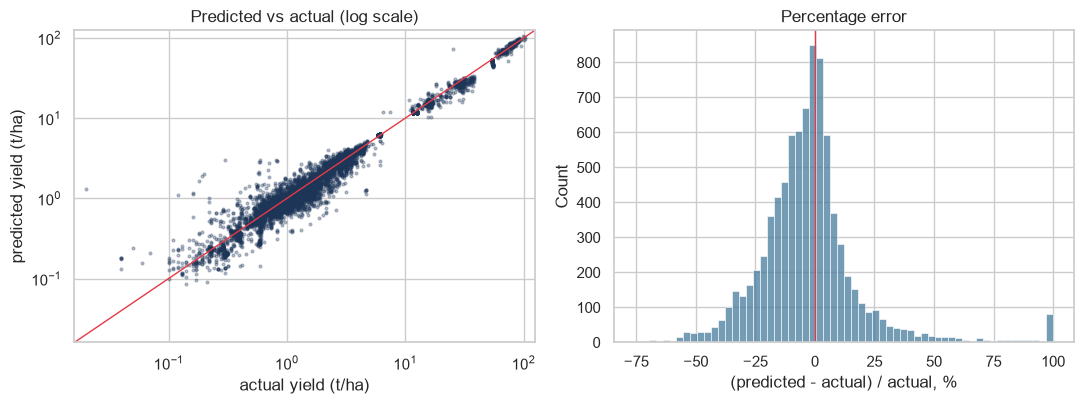

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].scatter(y_test, model_a_pred, s=4, alpha=0.3, color="#1d3557")
lims = [y_test.min() * 0.8, y_test.max() * 1.2]
axes[0].plot(lims, lims, color="#e63946", lw=1)
axes[0].set(xscale="log", yscale="log", xlim=lims, ylim=lims, title="Predicted vs actual (log scale)",
            xlabel="actual yield (t/ha)", ylabel="predicted yield (t/ha)")
ratio_error = (model_a_pred - y_test) / y_test * 100
sns.histplot(ratio_error.clip(-100, 100), bins=60, ax=axes[1], color="#457b9d")
axes[1].axvline(0, color="#e63946", lw=1)
axes[1].set(title="Percentage error", xlabel="(predicted - actual) / actual, %")
plt.tight_layout()
plt.show()

### Error by crop

In [66]:
ape = (model_a_pred - y_test).abs() / y_test
by_crop = pd.DataFrame({"rows": X_test.groupby("crop").size(),
                        "actual_median_t_ha": y_test.groupby(X_test["crop"]).median(),
                        "MAPE_%": ape.groupby(X_test["crop"]).mean() * 100,
                        "median_APE_%": ape.groupby(X_test["crop"]).median() * 100,
                        "accuracy_within_20%": (ape <= 0.2).groupby(X_test["crop"]).mean() * 100}).round(2)
by_crop.sort_values("accuracy_within_20%", ascending=False)

,rows,actual_median_t_ha,MAPE_%,median_APE_%,accuracy_within_20%
crop,,,,,
Banana,57,54.28,8.50,5.95,100.00
Guar seed,145,0.72,2.22,1.81,100.00
Ginger,12,4.56,7.18,6.98,100.00
Garlic,146,6.06,2.55,2.65,100.00
Dry chillies,178,0.89,3.34,1.83,100.00
Sweet potato,155,11.58,2.99,2.13,100.00
Sugarcane,224,77.74,5.64,3.90,99.11
Coriander,162,0.76,8.00,7.33,98.77
Wheat,375,3.79,5.57,4.36,97.87


### Error by test year

In [67]:
by_year_test = pd.DataFrame({"rows": X_test.groupby("crop_year_start").size(),
                             "MAPE_%": ape.groupby(X_test["crop_year_start"]).mean() * 100,
                             "median_APE_%": ape.groupby(X_test["crop_year_start"]).median() * 100,
                             "accuracy_within_20%": (ape <= 0.2).groupby(X_test["crop_year_start"]).mean() * 100}).round(2)
by_year_test

,rows,MAPE_%,median_APE_%,accuracy_within_20%
crop_year_start,,,,
2020,1901,14.76,9.88,78.54
2021,1824,14.08,7.58,80.15
2022,1888,13.67,7.72,79.40
2023,1385,17.53,12.41,70.11
2024,1418,25.35,12.43,70.38


### Accuracy on district-measured yields vs repeated figures

In [68]:
kind = repeated_test.map({True: "repeated figure", False: "district-measured"})
pd.DataFrame({"rows": ape.groupby(kind).size(),
              "MAPE_%": ape.groupby(kind).mean() * 100,
              "accuracy_within_20%": (ape <= 0.2).groupby(kind).mean() * 100}).round(2)

,rows,MAPE_%,accuracy_within_20%
yield_repeated,,,
district-measured,5857,19.10,72.46
repeated figure,2559,10.92,85.15


### Reliable crops: chosen by cross-validation on the training years

In [69]:
out_of_fold = []
for fit_idx, val_idx in year_folds:
    fold_model = clone(model_a_estimator).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    out_of_fold.append(pd.Series(fold_model.predict(X_train.iloc[val_idx]), index=X_train.index[val_idx]))
out_of_fold = pd.concat(out_of_fold)
cv_ok = (out_of_fold - y_train.loc[out_of_fold.index]).abs() / y_train.loc[out_of_fold.index] <= 0.20
cv_crop = cv_ok.groupby(X_train.loc[out_of_fold.index, "crop"])

reliability = pd.DataFrame({"cv_rows": cv_crop.size(),
                            "cv_accuracy_within_20%": cv_crop.mean() * 100,
                            "test_rows": X_test.groupby("crop").size(),
                            "test_accuracy_within_20%": (ape <= 0.2).groupby(X_test["crop"]).mean() * 100,
                            "repeated_figures_%": fe.groupby("crop")["yield_repeated"].mean() * 100})
reliability["reliable"] = (reliability["cv_accuracy_within_20%"] >= 70) & (reliability["cv_rows"] >= 100)
reliable_crops = reliability.index[reliability["reliable"]].tolist()
reliability.sort_values("cv_accuracy_within_20%", ascending=False).round(1)

,cv_rows,cv_accuracy_within_20%,test_rows,test_accuracy_within_20%,repeated_figures_%,reliable
crop,,,,,,
Guar seed,414.0,100.0,145.0,100.0,52.5,True
Sweet potato,462.0,99.8,155.0,100.0,72.9,True
Dry chillies,508.0,99.6,178.0,100.0,71.0,True
Sugarcane,668.0,96.0,224.0,99.1,0.0,True
Garlic,416.0,88.9,146.0,100.0,69.7,True
Rice,837.0,88.5,482.0,90.9,3.6,True
Banana,262.0,86.3,57.0,100.0,35.8,True
Wheat,669.0,80.3,375.0,97.9,0.0,True
Coriander,477.0,76.9,162.0,98.8,59.9,True


### Accuracy on reliable crops vs the other crops (test years)

In [70]:
tier = X_test["crop"].isin(reliable_crops).map({True: "reliable crops", False: "other crops"})
measured = ~repeated_test
tiers = pd.DataFrame({"crops": X_test["crop"].groupby(tier).nunique(),
                      "rows": ape.groupby(tier).size(),
                      "accuracy_within_20%": (ape <= 0.2).groupby(tier).mean() * 100,
                      "district_measured_accuracy_%": (ape[measured] <= 0.2).groupby(tier[measured]).mean() * 100,
                      "MAPE_%": ape.groupby(tier).mean() * 100,
                      "share_of_cropped_area_%": area_test.groupby(tier).sum() / area_test.sum() * 100}).round(1)
print(len(reliable_crops), "reliable crops:", reliable_crops)
tiers

11 reliable crops: ['Banana', 'Barley', 'Coriander', 'Dry chillies', 'Garlic', 'Guar seed', 'Maize', 'Rice', 'Sugarcane', 'Sweet potato', 'Wheat']


,crops,rows,accuracy_within_20%,district_measured_accuracy_%,MAPE_%,share_of_cropped_area_%
crop,,,,,,
other crops,22,5330,68.6,64.7,20.0,23.0
reliable crops,11,3086,89.6,86.8,10.8,77.0


### Ranking accuracy: are the crops of a district and season put in the right order?

In [71]:
def ranking_accuracy(name, pred):
    table = pd.DataFrame({"district": district_test, "season": X_test["season"], "year": X_test["crop_year_start"],
                          "actual": y_test, "pred": np.asarray(pred),
                          "price": fe.loc[X_test.index, "price_harvest_state_median"]})
    row = {"model": name}
    for label, frame in [("yield", table), ("revenue", table.dropna(subset=["price"]))]:
        rank_corr, top_correct = [], []
        for _, g in frame.groupby(["district", "season", "year"]):
            if len(g) >= 3:
                factor = g["price"] if label == "revenue" else 1
                actual, predicted = g["actual"] * factor, g["pred"] * factor
                rank_corr.append(spearmanr(actual, predicted)[0])
                top_correct.append(actual.idxmax() == predicted.idxmax())
        row[f"{label}_groups"] = len(top_correct)
        row[f"{label}_rank_correlation"] = np.nanmean(rank_corr)
        row[f"{label}_top_crop_correct_%"] = np.mean(top_correct) * 100
    return row

pd.DataFrame([ranking_accuracy(MEDIAN_BASELINE, median_baseline(X_test)),
              ranking_accuracy(HISTORY_BASELINE, history_baseline(X_test)),
              ranking_accuracy(MODEL_A, model_a_pred)]).set_index("model").round(3)

,yield_groups,yield_rank_correlation,yield_top_crop_correct_%,revenue_groups,revenue_rank_correlation,revenue_top_crop_correct_%
model,,,,,,
Baseline: crop-season median,1047,0.909,95.224,984,0.610,70.122
Baseline: district's previous 3 years,1047,0.922,94.174,984,0.698,73.374
"Model A: XGBoost (history-adjusted), 30 features",1047,0.929,95.511,984,0.702,75.305


### Permutation importance (test years)

yield_recent_mean: accuracy falls by 63.9 points when shuffled


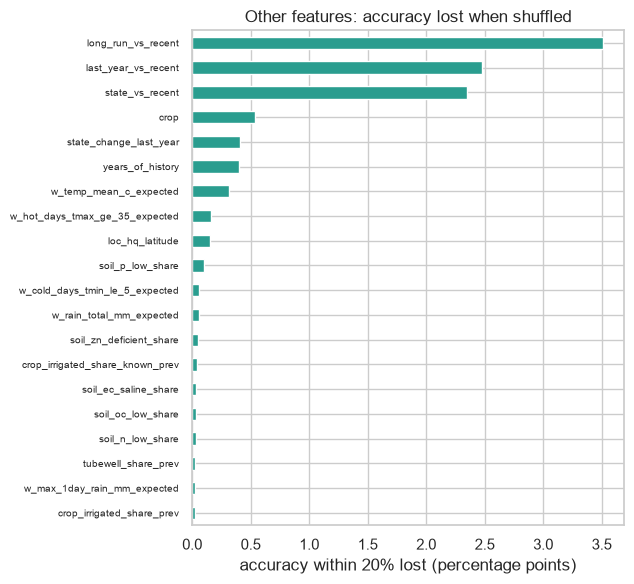

In [72]:
perm = permutation_importance(model_a, X_test[model_a_columns], y_test, n_repeats=5, random_state=42,
                              scoring=within_20, n_jobs=1)
importance = pd.Series(perm.importances_mean * 100, index=model_a_columns).sort_values(ascending=False)
print(f"yield_recent_mean: accuracy falls by {importance['yield_recent_mean']:.1f} points when shuffled")

fig, ax = plt.subplots(figsize=(6.5, 6))
importance.drop("yield_recent_mean").head(20).sort_values().plot.barh(ax=ax, color="#2a9d8f")
ax.set(title="Other features: accuracy lost when shuffled", xlabel="accuracy within 20% lost (percentage points)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

### Prediction ranges: an 80% range per crop from cross-validation errors

In [73]:
cv_error = np.log(y_train.loc[out_of_fold.index] / out_of_fold)
cv_error_crop = X_train.loc[out_of_fold.index, "crop"]
pooled = cv_error.quantile([0.10, 0.90])
crop_range = cv_error.groupby(cv_error_crop).quantile([0.10, 0.90]).unstack()
crop_range.loc[cv_error.groupby(cv_error_crop).size() < 100] = pooled.to_numpy()

range_low = model_a_pred * np.exp(X_test["crop"].map(crop_range[0.10]).fillna(pooled[0.10]))
range_high = model_a_pred * np.exp(X_test["crop"].map(crop_range[0.90]).fillna(pooled[0.90]))
inside = (y_test >= range_low) & (y_test <= range_high)

print(f"Actual yield inside the predicted range: {inside.mean():.1%} of test rows")
print("By test year:", (inside.groupby(X_test["crop_year_start"]).mean() * 100).round(1).to_dict())
ranges = pd.DataFrame({"range_low_%": (np.exp(crop_range[0.10]) - 1) * 100,
                       "range_high_%": (np.exp(crop_range[0.90]) - 1) * 100,
                       "test_rows": inside.groupby(X_test["crop"]).size(),
                       "inside_range_%": inside.groupby(X_test["crop"]).mean() * 100}).round(1)
ranges.sort_values("range_high_%")

Actual yield inside the predicted range: 85.6% of test rows
By test year: {2020: 83.9, 2021: 87.0, 2022: 87.0, 2023: 86.0, 2024: 84.1}


,range_low_%,range_high_%,test_rows,inside_range_%
crop,,,,
Turmeric,-60.4,0.2,46,15.2
Guar seed,-8.7,3.1,145,94.5
Sweet potato,-13.3,3.7,155,67.7
Banana,-16.0,10.1,57,64.9
Tobacco,-49.6,10.4,73,53.4
Garlic,-16.8,10.8,146,98.6
Sunflower,-61.3,11.6,92,84.8
Sugarcane,-8.3,12.2,224,87.9
Dry chillies,-11.3,13.8,178,100.0


### Sanity check: prediction and range for one district, season and year

In [74]:
def candidate_table(district, season, year):
    rows = X_test[(district_test == district) & (X_test["season"] == season) & (X_test["crop_year_start"] == year)]
    table = pd.DataFrame({"crop": rows["crop"],
                          "previous_3_years_t_ha": rows["yield_recent_mean"].round(2),
                          "predicted_t_ha": model_a_pred.loc[rows.index].round(2),
                          "range_low_t_ha": range_low.loc[rows.index].round(2),
                          "range_high_t_ha": range_high.loc[rows.index].round(2),
                          "actual_t_ha": y_test.loc[rows.index].round(2)})
    return table.sort_values("predicted_t_ha", ascending=False).reset_index(drop=True)

candidate_table("Agra", "Rabi", 2023)

,crop,previous_3_years_t_ha,predicted_t_ha,range_low_t_ha,range_high_t_ha,actual_t_ha
0,Wheat,4.18,4.37,3.19,5.26,4.23
1,Barley,3.49,3.66,2.18,4.70,3.40
2,Peas & beans (Pulses),2.67,2.28,1.50,3.17,2.74
3,Rapeseed & Mustard,2.13,2.08,1.45,2.69,1.89
4,Gram,1.59,1.45,0.62,2.47,1.88
5,Masoor,0.97,0.97,0.65,1.45,1.00


In [75]:
candidate_table("Gorakhpur", "Kharif", 2023)

,crop,previous_3_years_t_ha,predicted_t_ha,range_low_t_ha,range_high_t_ha,actual_t_ha
0,Rice,2.34,2.54,2.33,3.02,2.87
1,Jowar,1.09,1.21,0.82,1.76,1.60
2,Groundnut,0.83,0.89,0.68,1.24,1.94
3,Maize,0.48,0.85,0.66,1.08,1.89
4,Arhar/Tur,0.76,0.77,0.47,1.13,0.95
5,Small millets,0.74,0.74,0.59,1.02,0.89
6,Sesamum,0.25,0.20,0.12,0.36,0.30


### Final model: trained on the last 15 years only
The model that makes the predictions is trained on the most recent 15 years, so that it reflects recent farming conditions. Check on the test years: the same settings trained on the last 15 training years, next to the model trained on every training year.

In [76]:
FINAL_TRAIN_YEARS = 15

window_start = int(X_train["crop_year_start"].max()) - FINAL_TRAIN_YEARS + 1
in_window = X_train["crop_year_start"] >= window_start
window_model = clone(model_a_estimator).fit(X_train[in_window], y_train[in_window])
window_error = (window_model.predict(X_test) - y_test).abs() / y_test
all_error = (model_a_pred - y_test).abs() / y_test

window_check = pd.DataFrame({
    "train_years": [f"{int(X_train['crop_year_start'].min())}-{int(X_train['crop_year_start'].max())}",
                    f"{window_start}-{int(X_train['crop_year_start'].max())}"],
    "train_rows": [len(X_train), int(in_window.sum())],
    "accuracy_within_20%": [(all_error <= 0.20).mean() * 100, (window_error <= 0.20).mean() * 100],
    "MAPE_%": [all_error.mean() * 100, window_error.mean() * 100],
}, index=["Model A, every training year", "Model A, last {} training years".format(FINAL_TRAIN_YEARS)])
window_check.round(1)

,train_years,train_rows,accuracy_within_20%,MAPE_%
"Model A, every training year",1998-2019,36417,76.3,16.6
"Model A, last 15 training years",2005-2019,26859,75.7,16.7


## Save Model A

### Retrain on all years and save the model with everything the interface needs

In [77]:
def prediction_table(pred, actual, district, sample):
    rows = X.loc[pred.index]
    return pd.DataFrame({"district": district.loc[pred.index], "crop": rows["crop"], "season": rows["season"],
                         "crop_year_start": rows["crop_year_start"], "sample": sample,
                         "actual": actual.loc[pred.index], "predicted": pred})

past_predictions = pd.concat([prediction_table(out_of_fold, y_train, district_train, "cross-validation"),
                              prediction_table(model_a_pred, y_test, district_test, "test")], ignore_index=True)

recent = X["crop_year_start"] > X["crop_year_start"].max() - FINAL_TRAIN_YEARS
deployed_model = clone(model_a_estimator).fit(X[recent], y[recent])
test_error = (model_a_pred - y_test).abs() / y_test

bundle = {
    "model": deployed_model,
    "feature_columns": model_a_columns,
    "next_season": next_season,
    "next_season_label": next_label,
    "crop_range": crop_range.rename(columns={0.10: "low", 0.90: "high"}),
    "pooled_range": {"low": pooled[0.10], "high": pooled[0.90]},
    "reliable_crops": reliable_crops,
    "past_predictions": past_predictions,
    "trained_on_years": (int(X.loc[recent, "crop_year_start"].min()), int(X["crop_year_start"].max())),
    "window_check": window_check.round(1).to_dict("index"),
    "test_metrics": {"test_years": "2020-2024",
                     "accuracy_within_20%": round(float((test_error <= 0.20).mean() * 100), 1),
                     "MAPE_%": round(float(test_error.mean() * 100), 1),
                     "inside_80%_range_%": round(float(inside.mean() * 100), 1)},
}
Path("models").mkdir(exist_ok=True)
joblib.dump(bundle, "models/model_a.joblib")
print("Saved models/model_a.joblib:", round(Path("models/model_a.joblib").stat().st_size / 1e6, 1), "MB")
print("Trained on", bundle["trained_on_years"], "| predicts", next_label, "|", bundle["test_metrics"])

Saved models/model_a.joblib: 6.3 MB
Trained on (2010, 2024) | predicts 2025-26 | {'test_years': '2020-2024', 'accuracy_within_20%': 76.3, 'MAPE_%': 16.6, 'inside_80%_range_%': 85.6}


### Check the saved model through the interface function

In [78]:
predict_yields("Agra", "Rabi")

,crop_year,recent_average_t_ha,predicted_t_ha,range_low_t_ha,range_high_t_ha,reliable,farm_factor,basis,farm_predicted_t_ha,farm_range_low_t_ha,farm_range_high_t_ha
crop,,,,,,,,,,,
Potato,2025-26,36.10,36.23,27.43,46.80,False,1.0,district average,36.23,27.43,46.80
Onion,2025-26,15.55,16.44,11.97,21.52,False,1.0,district average,16.44,11.97,21.52
Garlic,2025-26,6.05,6.12,5.09,6.78,True,1.0,district average,6.12,5.09,6.78
Wheat,2025-26,4.20,4.19,3.06,5.05,True,1.0,district average,4.19,3.06,5.05
Barley,2025-26,3.27,3.11,1.85,3.99,True,1.0,district average,3.11,1.85,3.99
Peas & beans (Pulses),2025-26,2.51,2.52,1.66,3.50,False,1.0,district average,2.52,1.66,3.50
Rapeseed & Mustard,2025-26,1.91,1.92,1.33,2.48,False,1.0,district average,1.92,1.33,2.48
Gram,2025-26,1.64,1.71,0.73,2.90,False,1.0,district average,1.71,0.73,2.90
Masoor,2025-26,1.00,1.04,0.70,1.56,False,1.0,district average,1.04,0.70,1.56


In [79]:
predict_yields("Agra", "Rabi", farmer_yields={"Wheat": 3.6, "Rapeseed & Mustard": 1.9})

,crop_year,recent_average_t_ha,predicted_t_ha,range_low_t_ha,range_high_t_ha,reliable,farm_factor,basis,farm_predicted_t_ha,farm_range_low_t_ha,farm_range_high_t_ha
crop,,,,,,,,,,,
Potato,2025-26,36.10,36.23,27.43,46.80,False,0.93,farmer's other crops,33.69,25.51,43.52
Onion,2025-26,15.55,16.44,11.97,21.52,False,0.93,farmer's other crops,15.29,11.13,20.01
Garlic,2025-26,6.05,6.12,5.09,6.78,True,0.93,farmer's other crops,5.69,4.73,6.31
Wheat,2025-26,4.20,4.19,3.06,5.05,True,0.86,farmer's own yield,3.60,2.63,4.34
Barley,2025-26,3.27,3.11,1.85,3.99,True,0.93,farmer's other crops,2.89,1.72,3.71
Peas & beans (Pulses),2025-26,2.51,2.52,1.66,3.50,False,0.93,farmer's other crops,2.34,1.54,3.26
Rapeseed & Mustard,2025-26,1.91,1.92,1.33,2.48,False,0.99,farmer's own yield,1.90,1.32,2.46
Gram,2025-26,1.64,1.71,0.73,2.90,False,0.93,farmer's other crops,1.59,0.68,2.70
Masoor,2025-26,1.00,1.04,0.70,1.56,False,0.93,farmer's other crops,0.97,0.65,1.45
